# Marketplace Product Analysis (Capstone project, part 1) / Продуктовый анализ маркетплейса (Выпускной проект, часть 1)

Conclusions in English can be found at the end of the document.

Я работаю с быстрорастущим маркетплейсом, который уже нашёл свою нишу и начал приносить прибыль. Монетизация у маркетплейса работает так: он забирает комиссию 5% с каждой покупки пользователей.

До недавнего времени здесь обходились отчётами в Excel, ориентировались на бухгалтерские сводки и интуицию. Но бизнес растёт, и стало понятно, что нужны настоящие продуктовые данные, системный взгляд и аналитика, которая не просто описывает проект, а развивает его.

Команда хотела понять, как чувствует себя продукт: кто приходит, кто остаётся, кто платит, кто уходит. А ещё: на каких каналах держится рост, какие категории товаров приносят деньги, а какие висят мёртвым грузом. Мне нужно было погрузиться в данные и собрать целостную картину: от первых шагов пользователей до монетизации и возврата. При этом важно не просто вычислить сухие значения метрик, а найти в них смысл. 

Результаты этого анализа стали основой для A/B-теста во [второй части проекта](AB%20Test%20of%20a%20First-Purchase%20Bonus%20for%20TikTok%20Users.ipynb).

## Цель проекта

Собрать целостную картину состояния продукта - от первых шагов пользователей до монетизации и возврата - и найти точки роста.

**Задачи:**
1. Загрузить и предобработать данные о пользователях, заказах, событиях и маркетинговых расходах за 2024 год.
2. Оценить динамику ключевых продуктовых метрик: выручки, количества заказов, среднего чека, DAU, конверсии в покупку, привлечения новых пользователей и удержания.
3. Оценить монетизацию и юнит-экономику: ARPU, ARPPU, LTV, CAC, ROI и срок окупаемости по когортам.
4. Изучить данные в разрезе каналов привлечения, сегментов пользователей и товаров, построить продуктовую воронку и найти этапы, на которых теряются пользователи.
5. Сформулировать выводы, рекомендации и гипотезы для развития продукта.

# Расчёт метрик

### 1. Загрузить и предобработать данные

In [1]:
# Импортируем необходимые библиотеки
import pandas as pd # версия 2.3.3
import matplotlib.pyplot as plt # версия 3.9.4
import scipy # версия 1.13.1
import statsmodels # версия 0.14.6
import numpy as np # версия 2.0.2
import seaborn as sns # версия 0.13.2
import matplotlib.colors as mcolors

from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest

In [3]:
# Выведем данные, чтобы поверхностно изучить их
print('ORDERS')
print()
pa_marketplace_orders.info()
display(pa_marketplace_orders.head())

print()

print('CAMPAIGN COSTS')
print()
pa_marketplace_campaign_costs.info()
display(pa_marketplace_campaign_costs.head())

ORDERS

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.4+ MB


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01



CAMPAIGN COSTS

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Unnamed: 0   88 non-null     int64         
 1   acq_channel  88 non-null     object        
 2   spend_month  88 non-null     datetime64[ns]
 3   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ KB


,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750


In [4]:
print('USERS')
print()
pa_marketplace_users.info()
display(pa_marketplace_users.head())

print()

print('EVENTS')
print()
pa_marketplace_events.info()
display(pa_marketplace_events.head())

USERS

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01



EVENTS

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 54.0+ MB


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


In [5]:
pa_marketplace_campaign_costs.describe()

,Unnamed: 0,spend_month,budget
count,88.000000,88,8.800000e+01
mean,43.500000,2024-06-26 09:49:05.454545408,2.196269e+05
min,0.000000,2024-01-01 00:00:00,6.674101e+03
25%,21.750000,2024-04-01 00:00:00,4.204593e+04
50%,43.500000,2024-07-01 00:00:00,1.114376e+05
75%,65.250000,2024-10-01 00:00:00,1.726050e+05
max,87.000000,2025-01-01 00:00:00,1.533683e+06
std,25.547342,NaN,3.373531e+05


In [6]:
pa_marketplace_campaign_costs = pa_marketplace_campaign_costs[pa_marketplace_campaign_costs['spend_month'] < '2025-01-01']

In [7]:
# Проверим, есть ли в данных дубликаты
print('Дубликаты в pa_marketplace_orders: ', pa_marketplace_orders.duplicated().sum())
print('Дубликаты в pa_marketplace_campaign_costs: ', pa_marketplace_campaign_costs.duplicated().sum())
print('Дубликаты в pa_marketplace_users: ', pa_marketplace_users.duplicated().sum())
print('Дубликаты в pa_marketplace_events: ', pa_marketplace_events.duplicated().sum())

Дубликаты в pa_marketplace_orders:  0
Дубликаты в pa_marketplace_campaign_costs:  0
Дубликаты в pa_marketplace_users:  0
Дубликаты в pa_marketplace_events:  0


In [8]:
# Изучим, какие события есть в таблице событий
print(pa_marketplace_events['event_type'].unique())

['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']


In [9]:
# Посмотрим, какие каналы привлечения есть у продукта
print(pa_marketplace_campaign_costs['acq_channel'].unique())

['Affiliate' 'Direct' 'Email Marketing' 'Social Media' 'Google Ads' 'SEO'
 'TikTok']


In [10]:
# Проверим, есть ли дубликаты по user_id в таблице users
print(pa_marketplace_users['user_id'].duplicated().sum())

0


### 2. Построить обзор ключевых метрик

На этом этапе вам нужно выполнить верхнеуровневую оценку состояния продукта с помощью собранных витрин. Бизнес просит просто оценить текущее состояние — без глубокой сегментации и оценки сложных метрик.

Выручка бизнеса — 5% комиссии от стоимости любой продажи.

Посмотрите на общую динамику ключевых метрик: например, Revenue, ARPU или ARPPU, MAU, WAU, DAU, AOV, Retention, CTR, CR в заказ. Следовать этому списку необязательно, исходите из данных.

Ваша цель — быстро получить целостную картину, не применяя сегментацию и не рассматривая глубокие срезы. Определите, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы.

Результатом задания будет ваш вывод о динамике основных продуктовых метрик.

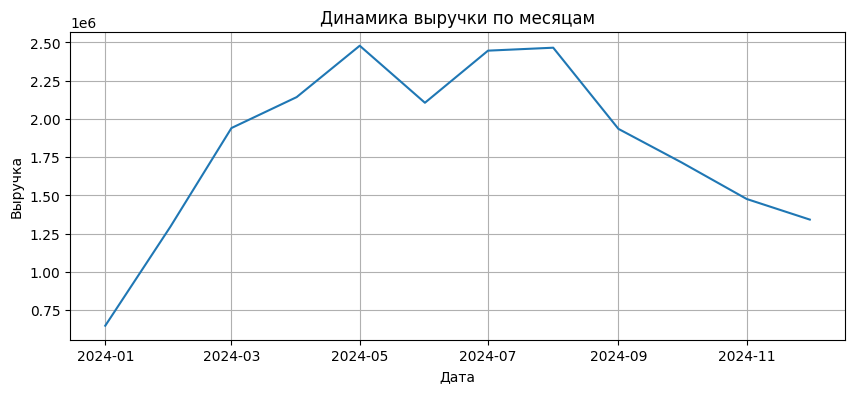

In [11]:
# Посмотрим на выручку компании

# Составим таблицу с динамикой выручки по месяцам
revenue_df = pa_marketplace_orders.groupby('order_month')['total_price'].sum().reset_index()
revenue_df['revenue'] = revenue_df['total_price'] * 0.05

# Построим график динамики выручки по месяцам
plt.figure(figsize=(10,4))
plt.plot(revenue_df['order_month'], revenue_df['revenue'])
plt.title('Динамика выручки по месяцам')
plt.xlabel('Дата')
plt.ylabel('Выручка')
plt.grid()
plt.show()

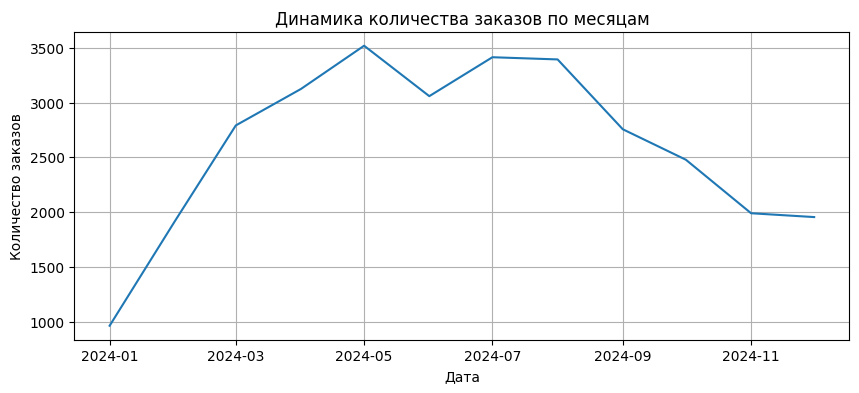

In [12]:
# Посмотрим на количество заказов

# Составим таблицу с количеством заказов по месяцам
orders_month_df = pa_marketplace_orders.groupby('order_month')['order_id'].nunique().reset_index(name='orders_count')

# Построим график динамики количества заказов по месяцам
plt.figure(figsize=(10,4))
plt.plot(orders_month_df['order_month'], orders_month_df['orders_count'])
plt.title('Динамика количества заказов по месяцам')
plt.xlabel('Дата')
plt.ylabel('Количество заказов')
plt.grid()
plt.show()

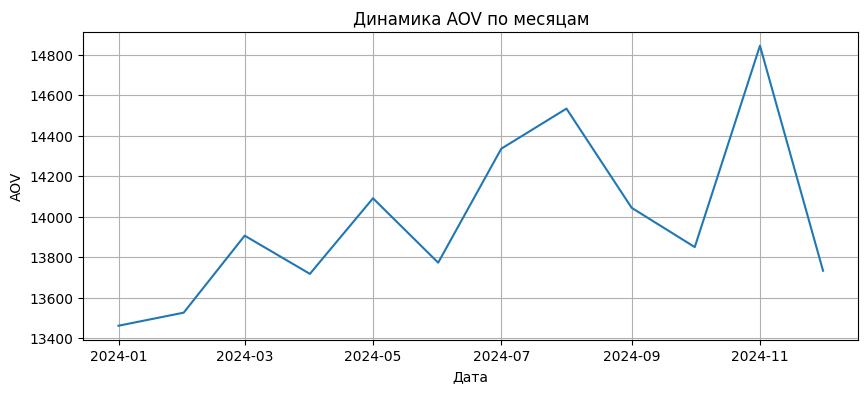

In [13]:
# Посмотрим на средний чек (AOV)

# Составим таблицу с динамикой AOV по месяцам из тех таблиц, что у нас уже есть
aov_df = pd.merge(revenue_df, orders_month_df, on='order_month', how='left')
aov_df['AOV'] = aov_df['total_price'] / aov_df['orders_count']

# Построим график динамики AOV по месяцам
plt.figure(figsize=(10,4))
plt.plot(aov_df['order_month'], aov_df['AOV'])
plt.title('Динамика AOV по месяцам')
plt.xlabel('Дата')
plt.ylabel('AOV')
plt.grid()
plt.show()

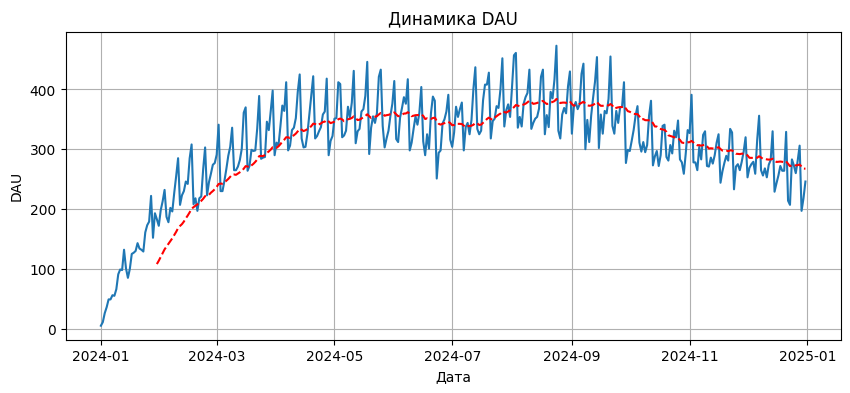

In [14]:
# Так как более яркое падение с августа наблюдается у количества заказов, проверим метрики, которые влияют на него
# Посмотрим на DAU

# Составим таблицу с DAU
daily_users = pa_marketplace_events.groupby('event_date')['user_id'].nunique().reset_index(name='users_count')

# Построим график динамики DAU
plt.figure(figsize=(10,4))
plt.plot(daily_users['event_date'], daily_users['users_count'])
plt.plot(daily_users['event_date'], daily_users['users_count'].rolling(window=30).mean(), color='red', linestyle='--') # скользящее среднее
plt.title('Динамика DAU')
plt.xlabel('Дата')
plt.ylabel('DAU')
plt.grid()
plt.show()

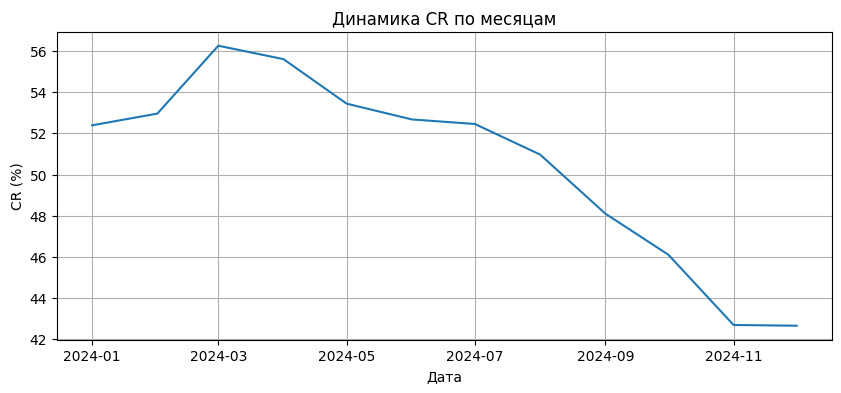

In [15]:
# Также посмотрим на CR - он тоже может быть связан с падением количества заказов

# Составим таблицу с общим количеством пользователей, которые проявляли активность
active_users = pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index(name='active_users_count')

# Составим таблицу с пользователями, которые выполнили целевое действие (название события - 'checkout_complete')
paying_users = (pa_marketplace_events[pa_marketplace_events['event_type'] == 'checkout_complete']
    .groupby('event_month')['user_id']
    .nunique()
    .reset_index(name='paying_users_count')
)

# Объединим две таблицы
cr_df = pd.merge(active_users, paying_users, on='event_month', how='left')
cr_df['paying_users_count'] = cr_df['paying_users_count'].fillna(0)

# Посчитаем CR за каждый месяц
cr_df['CR'] = cr_df['paying_users_count'] / cr_df['active_users_count'] * 100

# Построим график динамики CR по месяцам
plt.figure(figsize=(10,4))
plt.plot(cr_df['event_month'], cr_df['CR'])
plt.title('Динамика CR по месяцам')
plt.xlabel('Дата')
plt.ylabel('CR (%)')
plt.grid()
plt.show()

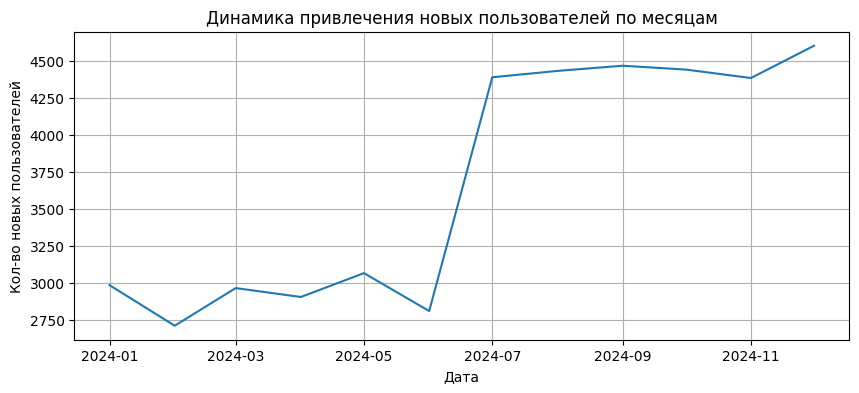

In [16]:
# Посмотрим на привлечение новых пользователей - насколько оно стабильно

# Составим таблицу с количеством новых пользователей по месяцам
new_users = pa_marketplace_users.groupby('cohort_month')['user_id'].nunique().reset_index(name='new_users_count')

# Построим график динамики привлечения новых пользователей по месяцам
plt.figure(figsize=(10,4))
plt.plot(new_users['cohort_month'], new_users['new_users_count'])
plt.title('Динамика привлечения новых пользователей по месяцам')
plt.xlabel('Дата')
plt.ylabel('Кол-во новых пользователей')
plt.grid()
plt.show()

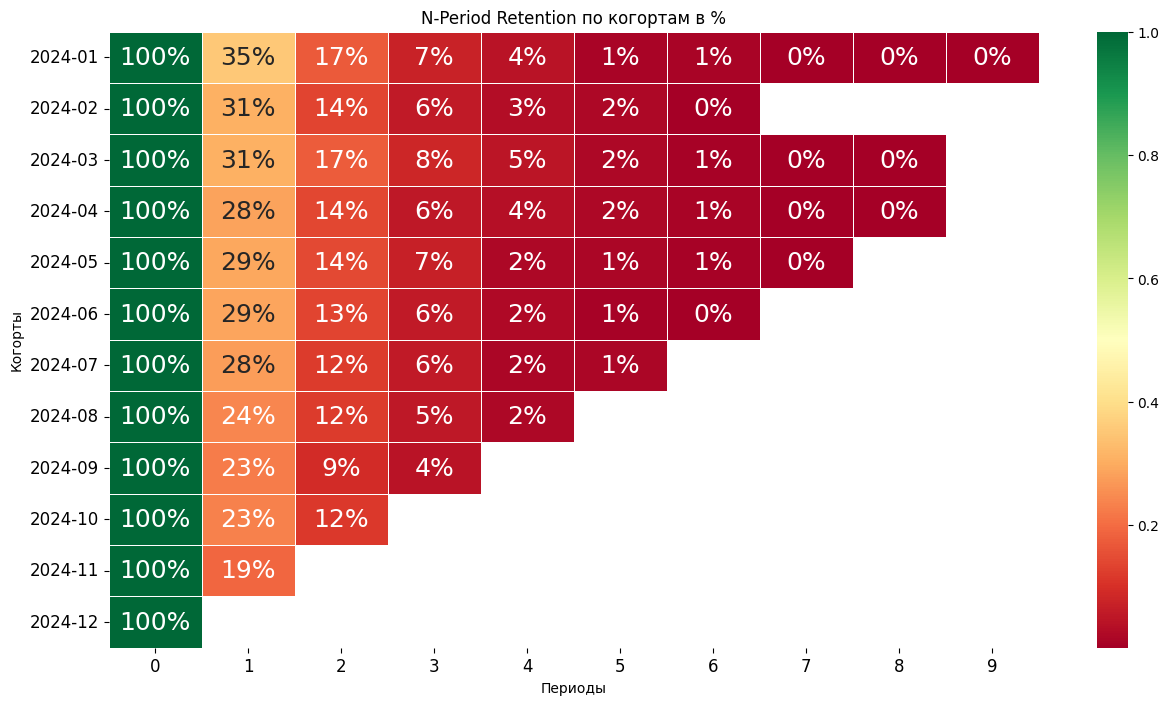

In [17]:
# Привлечение новых пользователей растёт, значит, возможно, дело в удержании старых - посмотрим на Retention Rate

# Создадим столбец с информацией о дате первого заказа пользователя
pa_marketplace_orders['first_order_month'] = pa_marketplace_orders.groupby('user_id')['order_date'].transform('min').dt.to_period('M')

# Посчитаем n_period - вычтем из месяца заказа месяц когорты
# Чтобы на выходе получить целочисленное значение, применим метод .astype('int64')
pa_marketplace_orders['n_period'] = (
    pa_marketplace_orders['order_date'].dt.to_period('M').astype('int64')
    - pa_marketplace_orders['first_order_month'].astype('int64')
)

# В индексе сводной таблицы будем выводить месяц первого заказа
# В колонках сводной таблицы выводим номер периода N, для которого считаем Retention
# Агрегируем по уникальным пользователям. Там, где данных нет, проставим 0 с помощью fillna()
data_pivot = pd.pivot_table(pa_marketplace_orders,
                            values='user_id',
                            index='first_order_month',
                            columns='n_period',
                            aggfunc=pd.Series.nunique).fillna(0).astype(int)

# Каждое значение строки датафрейма делим на значение в месяц первого заказа с помощью функции div()
data_pivot = data_pivot.div(data_pivot[0], axis=0)

# Заменяем нули на пустые значения NaN. Это необходимо для корректной отрисовки визуализации в дальнейшем.
# Чтобы нули не были видны на графиках, заменим их на NaN.
data_pivot[data_pivot == 0] = float('nan')

plt.subplots(figsize=(15,8))
sns.heatmap(data_pivot,
           annot=True,
           cmap="RdYlGn",
           fmt='.0%',
           linewidth=0.5,
           annot_kws={"size": 18})

# Остальные параметры совпадают с линейными графиками на matplotlib
plt.title('N-Period Retention по когортам в %')
plt.xlabel('Периоды')
plt.ylabel('Когорты')
plt.yticks(rotation=0)
plt.tick_params(labelsize=12) # чтобы сделать подписи данных на оси Y (когорты пользователей) немного крупнее
plt.show()

**Выводы**

Примерно с августа 2024 года у продукта падает выручка. С пика около 2,48 млн в мае она упала до около 1,35 млн в декабре.

Вероятнее всего, это связано с низким удержанием пользователей. Несмотря на то, что новые пользователи приходят в продукт регулярно и в больших количествах (с июля - почти 4500 человек ежемесячно), существующие довольно быстро выходят из продукта: буквально через 4 месяца в продукте остаётся менее 10% пользователей, а через 7-8 месяцев уходят все, кто пришёл. 

Средний чек в продукте колеблется в среднем от 13 500 до 14 800. И конверсия в покупку достаточно высокая (пик был в марте - около 56%), но тоже снижается, дойдя до примерно 43% в декабре. 

На первый взгляд, следует поработать над увеличением конверсии в покупку и Retention.

### 3. Оценка метрик монетизации и юнит-экономики

<div style="background-color: #fae8b6; padding: 10px;">
    
**Инструкция**

Выполните анализ монетизации. Определите, сколько зарабатывает продукт и сколько тратит на привлечение.

Важны как агрегированные метрики (ARPU, AOV), так и показатели эффективности (CAC, ROI, Payback Period).

Сформулируйте первые выводы по результатам анализа метрик. Сделайте это в формате записки для заказчика. Изложите все основные результаты так, чтобы прослеживалась связь между мыслями. Не пишите много — заказчик не будет читать записку полностью, а просто просмотрит.

Напишите выводы в конце блока, чтобы заказчик мог быстро ознакомиться с основными результатами.

</div>

,order_month,total_price,revenue,event_month,active_users_count,ARPU
0,2024-01-01,12977800.53,6.488900e+05,2024-01-01,1149,564.743278
1,2024-02-01,25931140.19,1.296557e+06,2024-02-01,2162,599.702595
2,2024-03-01,38814995.89,1.940750e+06,2024-03-01,2844,682.401475
3,2024-04-01,42856767.90,2.142838e+06,2024-04-01,3059,700.502908
4,2024-05-01,49575162.02,2.478758e+06,2024-05-01,3310,748.869517
5,2024-06-01,42120237.13,2.106012e+06,2024-06-01,3174,663.519804
6,2024-07-01,48930709.06,2.446535e+06,2024-07-01,3481,702.825468
7,2024-08-01,49316047.93,2.465802e+06,2024-08-01,3861,638.643459
8,2024-09-01,38707333.94,1.935367e+06,2024-09-01,3744,516.924866
9,2024-10-01,34322165.12,1.716108e+06,2024-10-01,3581,479.225986


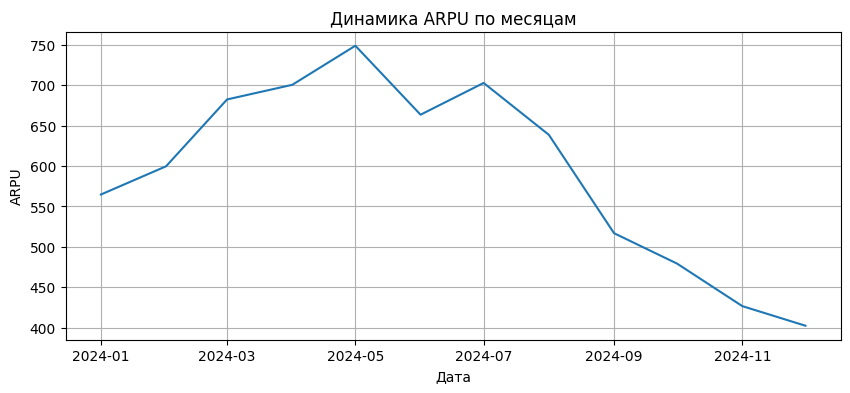

In [18]:
# Посмотрим на ARPU по месяцам

# Объединяем существующие таблицы, чтобы вычислить ARPU по месяцам
arpu_df = pd.merge(revenue_df, active_users, left_on='order_month', right_on='event_month', how='left')
arpu_df['ARPU'] = arpu_df['revenue'] / arpu_df['active_users_count']

display(arpu_df)

# Построим график динамики ARPU по месяцам
plt.figure(figsize=(10,4))
plt.plot(arpu_df['order_month'], arpu_df['ARPU'])
plt.title('Динамика ARPU по месяцам')
plt.xlabel('Дата')
plt.ylabel('ARPU')
plt.grid()
plt.show()

,order_month,total_price,revenue,paying_users_count,ARPPU
0,2024-01-01,12977800.53,6.488900e+05,454,28585.463722
1,2024-02-01,25931140.19,1.296557e+06,839,30907.199273
2,2024-03-01,38814995.89,1.940750e+06,1165,33317.593039
3,2024-04-01,42856767.90,2.142838e+06,1324,32369.160045
4,2024-05-01,49575162.02,2.478758e+06,1404,35309.944459
5,2024-06-01,42120237.13,2.106012e+06,1230,34244.095228
6,2024-07-01,48930709.06,2.446535e+06,1385,35329.031812
7,2024-08-01,49316047.93,2.465802e+06,1385,35607.254823
8,2024-09-01,38707333.94,1.935367e+06,1163,33282.316371
9,2024-10-01,34322165.12,1.716108e+06,999,34356.521642


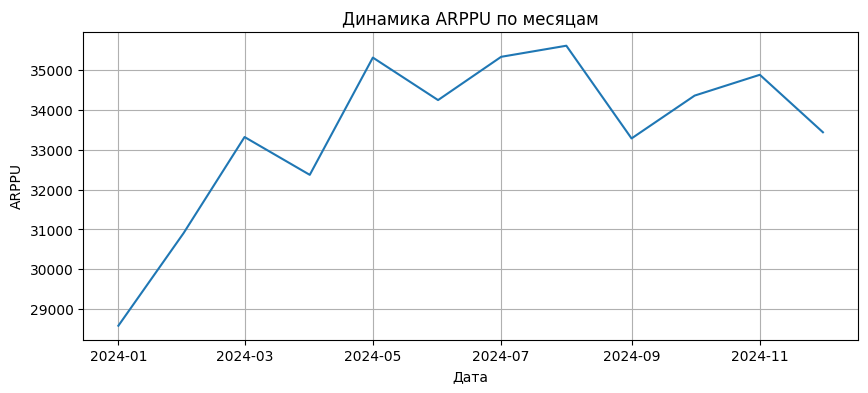

In [19]:
# Посмотрим на ARPPU по месяцам

# Составим таблицу с количеством пользователей, сделавших заказ, по месяцам
order_users = pa_marketplace_orders.groupby('order_month')['user_id'].nunique().reset_index(name='paying_users_count')

# Объединяем существующие таблицы, чтобы вычислить ARPPU по месяцам
arppu_df = pd.merge(revenue_df, order_users, on='order_month', how='left')
arppu_df['ARPPU'] = arppu_df['total_price'] / arppu_df['paying_users_count']

display(arppu_df)

# Построим график динамики ARPPU по месяцам
plt.figure(figsize=(10,4))
plt.plot(arppu_df['order_month'], arppu_df['ARPPU'])
plt.title('Динамика ARPPU по месяцам')
plt.xlabel('Дата')
plt.ylabel('ARPPU')
plt.grid()
plt.show()

,order_month,total_price,revenue,event_month,paying_users_count,ARPPU
0,2024-01-01,12977800.53,6.488900e+05,2024-01-01,602,21557.808189
1,2024-02-01,25931140.19,1.296557e+06,2024-02-01,1145,22647.284009
2,2024-03-01,38814995.89,1.940750e+06,2024-03-01,1600,24259.372431
3,2024-04-01,42856767.90,2.142838e+06,2024-04-01,1701,25195.042857
4,2024-05-01,49575162.02,2.478758e+06,2024-05-01,1769,28024.399107
5,2024-06-01,42120237.13,2.106012e+06,2024-06-01,1672,25191.529384
6,2024-07-01,48930709.06,2.446535e+06,2024-07-01,1826,26796.664326
7,2024-08-01,49316047.93,2.465802e+06,2024-08-01,1968,25058.967444
8,2024-09-01,38707333.94,1.935367e+06,2024-09-01,1801,21492.134336
9,2024-10-01,34322165.12,1.716108e+06,2024-10-01,1651,20788.712974


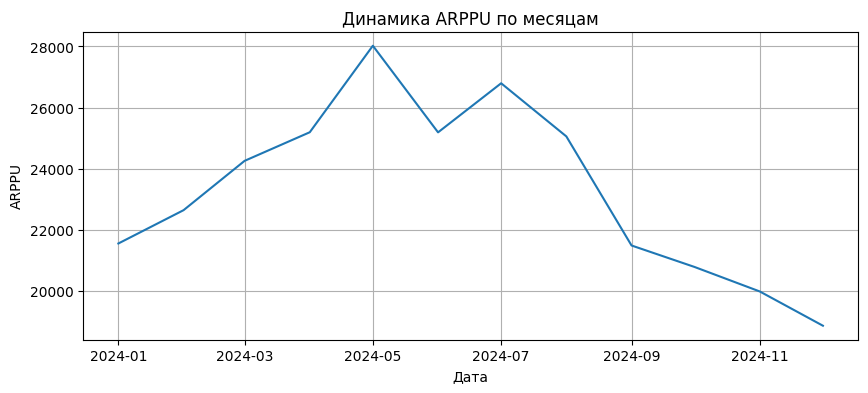

In [20]:
# Посмотрим на ARPPU другим способом (на всякий случай)

# Объединяем существующие таблицы, чтобы вычислить ARPPU по месяцам
# Теперь мы возьмём в качестве paying_users тех, у кого в таблице events стоит тип события checkout_complete
arppu_df2 = pd.merge(revenue_df, paying_users, left_on='order_month', right_on='event_month', how='left')
arppu_df2['ARPPU'] = arppu_df2['total_price'] / arppu_df2['paying_users_count']

display(arppu_df2)

# Построим график динамики ARPPU по месяцам
plt.figure(figsize=(10,4))
plt.plot(arppu_df2['order_month'], arppu_df2['ARPPU'])
plt.title('Динамика ARPPU по месяцам')
plt.xlabel('Дата')
plt.ylabel('ARPPU')
plt.grid()
plt.show()

In [21]:
# Присоединим к orders информацию о канале привлечения пользователя
pa_marketplace_orders = pd.merge(pa_marketplace_orders, 
                                 pa_marketplace_users[['user_id', 'acq_channel', 'cohort_month']], 
                                 on='user_id', 
                                 how='left')

# Создадим столбец n_month (у нас уже был n_period, но он рассчитывался от даты первого заказа, а сейчас нам нужна дата регистрации)
pa_marketplace_orders['n_month'] = (
    (pa_marketplace_orders['order_month'].dt.year - pa_marketplace_orders['cohort_month'].dt.year) * 12
    + (pa_marketplace_orders['order_month'].dt.month - pa_marketplace_orders['cohort_month'].dt.month)
)

# Создадим столбец с выручкой, которую получает маркетплейс от каждого заказа
pa_marketplace_orders['revenue'] = pa_marketplace_orders['total_price'] * 0.05

In [22]:
# Проверим, нет ли пропусков в канале привлечения

pa_marketplace_orders['acq_channel'].isna().sum()

np.int64(911)

In [23]:
# Узнаем больше о пропусках

missing = pa_marketplace_orders[pa_marketplace_orders['acq_channel'].isna()]

print('Строк с пропуском:', len(missing), 'из', len(pa_marketplace_orders))
print('Уникальных пользователей:', missing['user_id'].nunique())
print('Нет в таблице users:', (~missing['user_id'].isin(pa_marketplace_users['user_id'])).sum())
print('Есть в users, но канал пустой:', missing['user_id'].isin(pa_marketplace_users['user_id']).sum())
print('Доля выручки:', missing['revenue'].sum() / pa_marketplace_orders['revenue'].sum())

Строк с пропуском: 911 из 31357
Уникальных пользователей: 268
Нет в таблице users: 911
Есть в users, но канал пустой: 0
Доля выручки: 0.02947188681369779


In [24]:
# Посмотрим на LTV в продукте

# Посчитаем выручку по когортам и n_month и отсортируем в правильном порядке
cohort_rev = (
    pa_marketplace_orders.groupby(['cohort_month', 'n_month'])['revenue']
        .sum()
        .reset_index()
        .sort_values(by=['cohort_month', 'n_month'])
)

# Посчитаем накопленную выручку
cohort_rev['cum_revenue'] = cohort_rev.groupby('cohort_month')['revenue'].cumsum()

# Посчитаем количество пользователей по когортам
cohort_size = pa_marketplace_users.groupby('cohort_month')['user_id'].nunique().reset_index(name='cohort_size')

# Объединяем таблицы
ltv_df = pd.merge(cohort_rev, cohort_size, on='cohort_month', how='inner')

# Посчитаем LTV
ltv_df['LTV'] = ltv_df['cum_revenue'] / ltv_df['cohort_size']

display(ltv_df.head())

,cohort_month,n_month,revenue,cum_revenue,cohort_size,LTV
0,2024-01-01,0.0,623485.5890,6.234856e+05,2985,208.872894
1,2024-01-01,1.0,693054.8455,1.316540e+06,2985,441.052072
2,2024-01-01,2.0,413166.8270,1.729707e+06,2985,579.466419
3,2024-01-01,3.0,147712.2805,1.877420e+06,2985,628.951270
4,2024-01-01,4.0,153252.4020,2.030672e+06,2985,680.292109


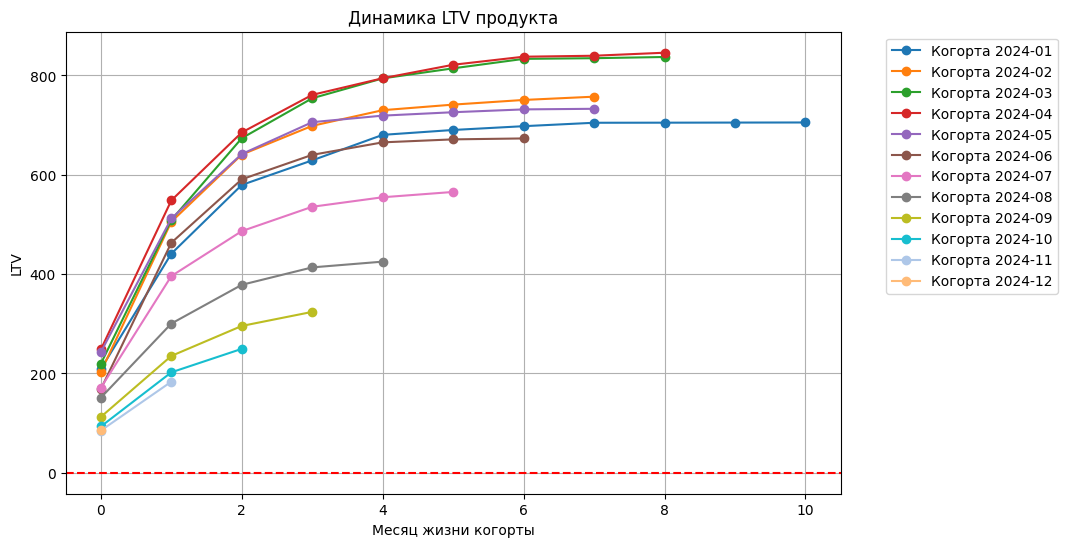

In [25]:
# Построим график LTV в продукте 

plt.figure(figsize=(10, 6))
cohorts = sorted(ltv_df['cohort_month'].unique())
colors = plt.cm.tab20(list(range(0, 20, 2)) + list(range(1, 20, 2)))

for i, month in enumerate(cohorts):
    df_plot = ltv_df[ltv_df['cohort_month'] == month]
    month_label = pd.Timestamp(month).strftime('%Y-%m')
    plt.plot(df_plot['n_month'], df_plot['LTV'], marker='o', color=colors[i], label=f'Когорта {month_label}')
        
plt.axhline(y=0, linestyle='--', color='red')
plt.title('Динамика LTV продукта')
plt.xlabel('Месяц жизни когорты')
plt.ylabel('LTV')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()    

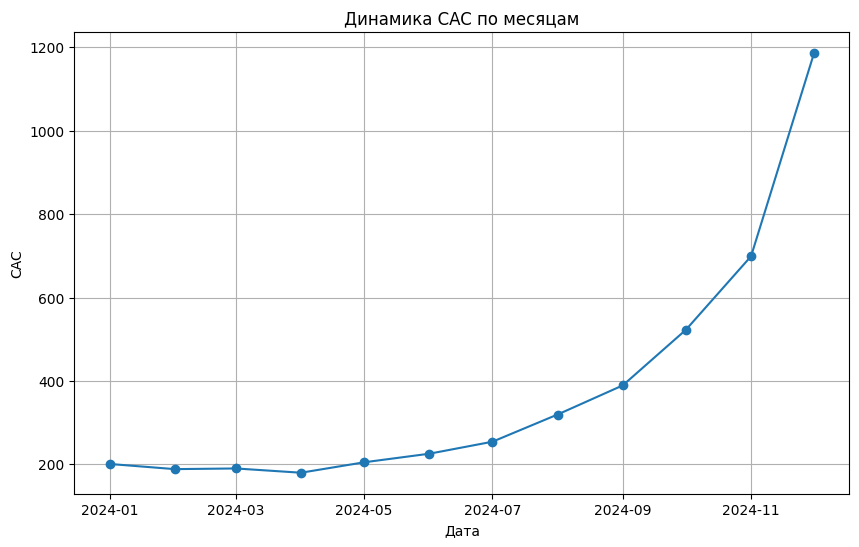

In [26]:
# Посмотрим на CAC в продукте

# Отфильтруем таблицу users: оставляем только платящих клиентов
unique_order_users = pa_marketplace_orders['user_id'].unique()
users_filtered = pa_marketplace_users[pa_marketplace_users['user_id'].isin(unique_order_users)]

# Считаем количество покупателей в каждой когорте
users_groupped = users_filtered.groupby('cohort_month')['user_id'].nunique().reset_index(name='unique_users_count')

# Объединяем датасеты по когорте
user_base = pd.merge(pa_marketplace_campaign_costs, users_groupped, left_on='spend_month', right_on='cohort_month', how='left')
user_base['unique_users_count'] = user_base['unique_users_count'].fillna(0)

# Суммируем количество клиентов и затраты за месяц
cac_df = user_base.groupby('spend_month').agg(
    cost=('budget', 'sum'),
    users_count=('unique_users_count', 'sum')
).reset_index()

# Cчитаем CAC
cac_df['CAC'] = cac_df['cost'] / cac_df['users_count']

# Построим график динамики CAC по месяцам
plt.figure(figsize=(10,6))
plt.plot(cac_df['spend_month'], cac_df['CAC'], marker='o')
plt.title('Динамика CAC по месяцам')
plt.xlabel('Дата')
plt.ylabel('CAC')
plt.grid()
    
plt.show()

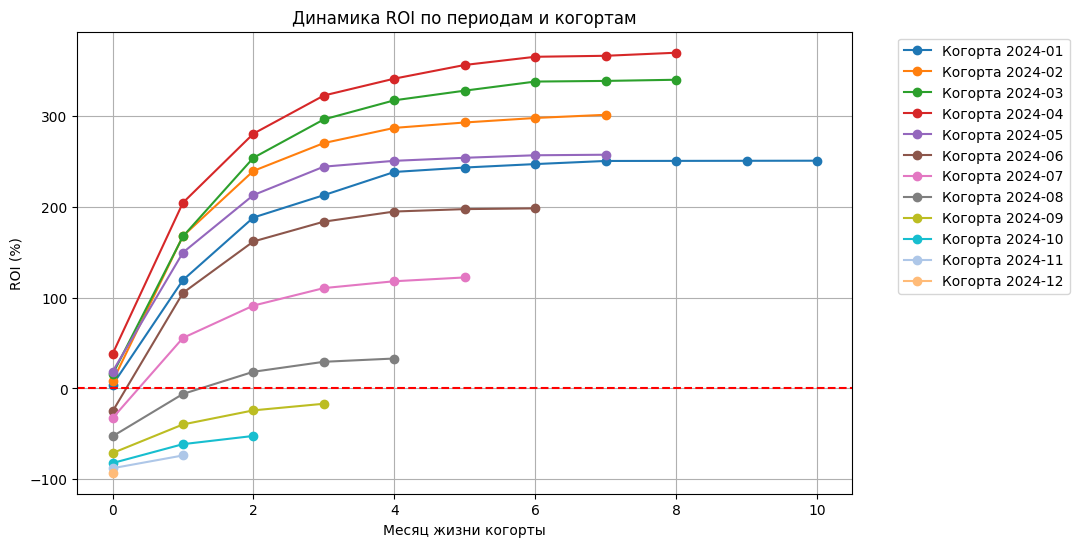

In [27]:
# Посмотрим на ROI в продукте

# Объединим созданные таблицы для расчёта ROI
roi_df = pd.merge(ltv_df, cac_df, left_on='cohort_month', right_on='spend_month', how='inner')

# Посчитаем ROI
roi_df['ROI'] = (roi_df['LTV'] - roi_df['CAC']) / roi_df['CAC'] * 100

# Добавим когорты и цвета
cohorts = sorted(roi_df['cohort_month'].unique())
colors = plt.cm.tab20(list(range(0, 20, 2)) + list(range(1, 20, 2)))

# Построим график динамики ROI по месяцам
plt.figure(figsize=(10,6))

for i, month in enumerate(cohorts):
    df_plot = roi_df[roi_df['cohort_month'] == month]
    month_label = pd.Timestamp(month).strftime('%Y-%m')
    plt.plot(df_plot['n_month'], df_plot['ROI'], color=colors[i], marker='o', label=f'Когорта {month_label}')
        
plt.axhline(y=0, linestyle='--', color='red')
plt.title('Динамика ROI по периодам и когортам')
plt.xlabel('Месяц жизни когорты')
plt.ylabel('ROI (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
    
plt.show() 

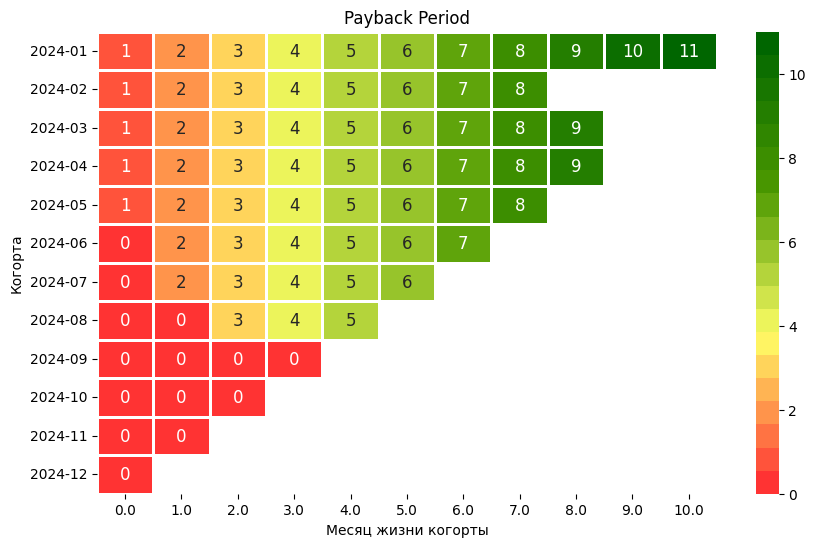

In [28]:
# Посмотрим на Payback Period

# Назначим цвета для тепловой карты
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)

# Рассчитываем payback period
roi_df['Payback_Period'] = roi_df.apply(lambda row: row['n_month'] + 1 if row['LTV'] >= row['CAC'] else 0, axis=1)

# Пивотируем данные
pp_pivot = roi_df.pivot(index='cohort_month', columns='n_month', values='Payback_Period')
pp_pivot.index = pp_pivot.index.strftime('%Y-%m')

# Строим график
plt.figure(figsize=(10,6))
sns.heatmap(pp_pivot, cmap=cmap, annot=True, fmt='.0f', linewidth=2, annot_kws={'size': 12})
plt.title('Payback Period')
plt.xlabel('Месяц жизни когорты')
plt.ylabel('Когорта')
plt.show()

**Выводы**

Средний чек пользователей составляет около 14 000, из них маркетплейсу уходит 5%, около 700. LTV клиентов составляет около 2500-2700. Если смотреть на динамику по месяцам, то примерно возле этой суммы она выходит на плато. LTV разных когорт варьируется, но нельзя сказать, что в последние месяцы он стал меньше или больше. 

Странно, что по-разному себя ведут ARPU и ARPPU:
- ARPPU (выручка на платящего) с весны держится примерно на одном уровне: около 33 000 – 35 000, без устойчивого падения.
- ARPU (выручка на активного пользователя) после июля падает: примерно с 14 000 до 8000 тысяч к декабрю.

ARPU можно разложить так: ARPU = ARPPU × доля платящих среди активных. Раз ARPPU стоит на месте, а ARPU падает, значит, падает доля платящих. При этом те, кто покупает, тратят столько же, сколько раньше.

Если смотреть по всему продукту, то стоимость рекламы окупается уже в месяц привлечения, - это отличный результат. Однако стоимость привлечения клиентов очень сильно растёт, и, вероятно, из-за этого процент ROI в более новых когортах постепенно падает. Нужно разобрать CAC в разрезе источников привлечения. Возможно, у каких-то источников завышенная стоимость и низкая эффективность - тогда ситуацию можно улучшить.

**Разработчикам: что проверить и исправить**

911 заказов сделаны пользователями, отсутствующими в справочнике пользователей. Эти заказы я учла в общей выручке, но не буду учитывать в анализе по каналам, так как каналы у них неизвестны. Рекомендую проверить, как синхронизируются данные, и выяснить, почему возникает такая ошибка.

Также я заметила, что количество заказов в таблицах orders и events не совпадает - это видно из графиков ARPPU, которые значительно различаются, если их считать разными способами. Вероятно, в events учитываются покупки, которые потом были возвращены, а в orders только полностью успешные. Тоже стоит проверить, так ли планировалось это учитывать.

## Выводы по этапам 2 и 3


**Общее**

Примерно с августа 2024 года у продукта падает выручка. С пика около 2,48 млн в мае она упала до около 1,35 млн в декабре.

**Хорошие показатели**

1. Средний чек пользователей стабилен - около 14 000, из них маркетплейсу уходит 5% - около 700.

2. Новые пользователи приходят в продукт регулярно и в больших количествах (с июля - почти 4500 человек ежемесячно).

3. Средняя сумма покупок на платящего пользователя (ARPPU) колеблется, но не падает. То есть те, кто покупает, тратят столько же, сколько раньше.

4. Когорты января-мая окупались уже в месяц привлечения, а к концу года их ROI достиг 250-370%.

**Проблемы продукта**

1. Несмотря на регулярный приток новых пользователей, существующие довольно быстро выходят из продукта: через 4 месяца в продукте остаётся менее 10% пользователей, а через 7-8 месяцев уходят все, кто пришёл.

2. В продукте падает доля платящих пользователей: ARPU снизился почти вдвое - примерно с 750 в мае до 400 в декабре.

3. Новые когорты приносят меньше денег: LTV августовской когорты на 4-м месяце почти вдвое ниже, чем у апрельской.

4. Стоимость привлечения клиентов выросла примерно в 6 раз - с 180-205 весной до около 1190 в декабре. Из-за этого новые когорты окупаются всё медленнее, а когорты сентября-декабря пока не окупились совсем. Возможно, у каких-то источников привлечения завышенная стоимость и низкая эффективность - если убрать их, ситуацию можно улучшить.

**Рекомендации**

- Поработать над увеличением конверсии в покупку и Retention.
- Разобрать CAC в разрезе источников привлечения и пересмотреть их.

**Разработчикам: что проверить и исправить**

911 заказов (около 3% выручки) сделаны пользователями, отсутствующими в справочнике пользователей. Эти заказы я учла в общей выручке, но не буду учитывать в анализе по каналам, так как каналы у них неизвестны. Рекомендую проверить, как синхронизируются данные, и выяснить, почему возникает такая ошибка.

Также я заметила, что количество заказов в таблицах orders и events не совпадает - это видно из графиков ARPPU, которые значительно различаются, если их считать разными способами. Вероятно, в events учитываются покупки, которые потом были возвращены, а в orders только полностью успешные. Тоже стоит проверить, так ли планировалось это учитывать.

## 4. Поиск инсайтов, точек роста и сегментация


<div style="background-color: #fae8b6; padding: 10px;">
    
**Инструкция**

После того как вы провели верхнеуровневую оценку данных, самое время переходить от общей картины к точечным наблюдениям. Посмотрите вглубь данных: по каналам,
сегментам пользователей, категориям товаров, регионам, типам устройств. Ищите
закономерности, различия, аномалии.

Цель — сформировать обоснованные гипотезы:

* какие сегменты работают лучше остальных
* какие сегменты работают хуже остальных
* на каких этапах воронки теряются пользователи
* какие группы можно или нужно масштабировать
* куда стоит инвестировать больше внимания или ресурсов

По итогам анализа также:

* сформулируйте в виде аналитической записки выводы
* сформулируйте несколько гипотез, которые помогут развить продукт. Например: «Если предлагать клиентам на iOS персонализированные скидки, то они станут чаще конвертировать в продукт». При формулировании гипотез опишите, на что вы опираетесь при её формировании. Например, на динамику метрики или на взаимосвязь метрик.

</div>

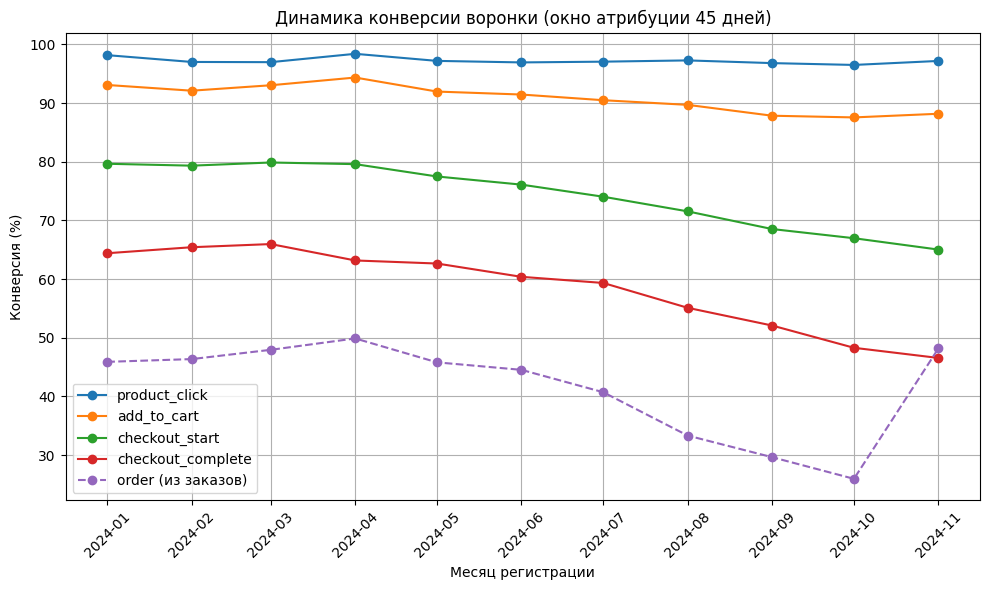

In [29]:
# Построим воронку, чтобы понять, какая конверсия у пользователей поэтапно

# Определяем окно атрибуции
attribution_window = 45

# Для дальнейших расчётов присоединим к датасету с событиями информацию о дате регистрации
pa_marketplace_events = pd.merge(pa_marketplace_events, pa_marketplace_users[['user_id', 'registration_date']], on='user_id', how='left')

# Считаем разницу в днях между датой регистрации и событием
pa_marketplace_events['diff_days'] = (pa_marketplace_events['event_date'] - pa_marketplace_events['registration_date']).dt.days

# Округляем даты регистраций до месяца
pa_marketplace_events['reg_month'] = pa_marketplace_events['registration_date'].dt.to_period('M').dt.to_timestamp()

# Чтобы не занижать результаты, оставим только тех пользователей, у кого дата регистрации не меньше 45 дней от последней даты в данных 
# (так как многие недавно зарегистрировавшиеся пользователи ещё не успели дойти до покупки)
max_date = pa_marketplace_events['event_date'].max()
events_old = pa_marketplace_events[(pa_marketplace_events['registration_date'] + pd.Timedelta(days=45)) <= max_date]

# Фильтруем события в пределах окна атрибуции
events_attribution = events_old[events_old['diff_days'].between(0, attribution_window - 1)]

# Выберем шаги, которые будем анализировать
funnel_steps = ['product_click', 'add_to_cart', 'checkout_start', 'checkout_complete']

# Считаем количество пользователей, установивших приложение, как количество уникальных в таблице с группировкой до месяца
funnel_dynamic = events_attribution.groupby('reg_month')['user_id'].nunique().reset_index(name='install_users')

# Построим динамичную продуктовую воронку
plt.figure(figsize=(10, 6))

for step in funnel_steps:
    df_step = events_attribution[events_attribution['event_type'] == step]
    df_step = df_step.groupby('reg_month')['user_id'].nunique().reset_index(name=step)
    funnel_dynamic = funnel_dynamic.merge(df_step, on='reg_month', how='left')
    funnel_dynamic[step] = (funnel_dynamic[step] / funnel_dynamic['install_users']) * 100
    
    # Добавляем линию на график
    plt.plot(funnel_dynamic['reg_month'], funnel_dynamic[step], marker='o', label=step)

# Оформление графика
plt.title('Динамика конверсии воронки (окно атрибуции 45 дней)')
plt.xlabel('Месяц регистрации')
plt.ylabel('Конверсия (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Также надо добавить в воронку "этап", который зафиксирован в orders, - он отличается от события checkout_complete

# Присоединим к заказам дату регистрации
orders_reg = pd.merge(
    pa_marketplace_orders.drop(columns=['registration_date'], errors='ignore'),
    pa_marketplace_users[['user_id', 'registration_date']],
    on='user_id', how='inner'
)

# Считаем разницу в днях между регистрацией и заказом
orders_reg['diff_days'] = (orders_reg['order_date'] - orders_reg['registration_date']).dt.days

# Месяц регистрации
orders_reg['reg_month'] = orders_reg['registration_date'].dt.to_period('M').dt.to_timestamp()

# Оставляем заказы в пределах окна атрибуции
orders_window = orders_reg[orders_reg['diff_days'].between(0, attribution_window)]

# Считаем уникальных покупателей по месяцу регистрации
df_order = orders_window.groupby('reg_month')['user_id'].nunique().reset_index(name='order')

# Добавляем шаг в воронку и переводим в проценты
funnel_dynamic = funnel_dynamic.merge(df_order, on='reg_month', how='left')
funnel_dynamic['order'] = funnel_dynamic['order'] / funnel_dynamic['install_users'] * 100

# Добавляем линию на график
plt.plot(funnel_dynamic['reg_month'], funnel_dynamic['order'], marker='o', linestyle='--', label='order (из заказов)')

plt.legend()
plt.show()

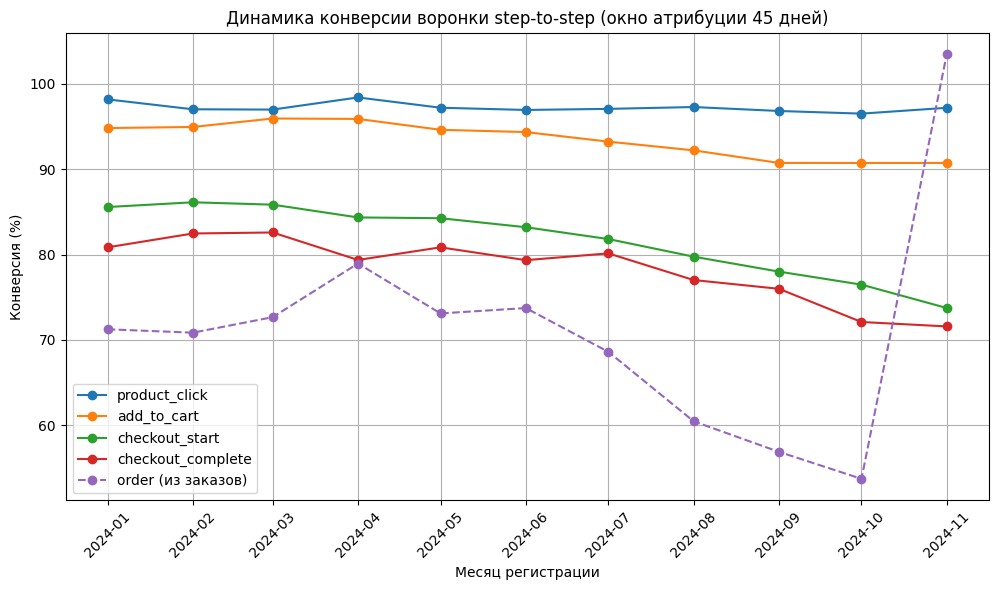

In [30]:
# Построим также воронку step-to-step

# Посчитаем количество пользователей, установивших приложение, как количество уникальных в таблице с группировкой до месяца
funnel_dynamic_step_to_step = events_attribution.groupby('reg_month')['user_id'].nunique().reset_index(name='install_users')

# Построим динамичную продуктовую воронку
plt.figure(figsize=(10, 6))

# Назначим предыдущий шаг - для первого шага это установки
prev_col = 'install_users'  

for step in funnel_steps:
    df_step = events_attribution[events_attribution['event_type'] == step]
    df_step = df_step.groupby('reg_month')['user_id'].nunique().reset_index(name=step)
    funnel_dynamic_step_to_step = funnel_dynamic_step_to_step.merge(df_step, on='reg_month', how='left')
    funnel_dynamic_step_to_step[f'{step}_conversion'] = funnel_dynamic_step_to_step[step] / funnel_dynamic_step_to_step[prev_col] * 100
    
    # Добавляем линию на график
    plt.plot(funnel_dynamic_step_to_step['reg_month'], funnel_dynamic_step_to_step[f'{step}_conversion'], marker='o', label=step)

    # Назначаем текущий шаг "предыдущим", чтобы в следующей итерации делить количество пользователей на него
    prev_col = step

# Оформление графика
plt.title('Динамика конверсии воронки step-to-step (окно атрибуции 45 дней)')
plt.xlabel('Месяц регистрации')
plt.ylabel('Конверсия (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Также надо добавить в воронку "этап", который зафиксирован в orders, - он отличается от события checkout_complete

# Присоединим к заказам дату регистрации
orders_reg = pd.merge(
    pa_marketplace_orders.drop(columns=['registration_date'], errors='ignore'),
    pa_marketplace_users[['user_id', 'registration_date']],
    on='user_id', how='inner'
)

# Считаем разницу в днях между регистрацией и заказом
orders_reg['diff_days'] = (orders_reg['order_date'] - orders_reg['registration_date']).dt.days

# Месяц регистрации
orders_reg['reg_month'] = orders_reg['registration_date'].dt.to_period('M').dt.to_timestamp()

# Оставляем заказы в пределах окна атрибуции
orders_window = orders_reg[orders_reg['diff_days'].between(0, attribution_window)]

# Считаем уникальных покупателей по месяцу регистрации
df_order = orders_window.groupby('reg_month')['user_id'].nunique().reset_index(name='order')

# Добавляем шаг в воронку и переводим в проценты
funnel_dynamic_step_to_step = funnel_dynamic_step_to_step.merge(df_order, on='reg_month', how='left')
funnel_dynamic_step_to_step['order_conversion'] = funnel_dynamic_step_to_step['order'] / funnel_dynamic_step_to_step['checkout_complete'] * 100

# Добавляем линию на график
plt.plot(funnel_dynamic_step_to_step['reg_month'], funnel_dynamic_step_to_step['order_conversion'], marker='o', linestyle='--', label='order (из заказов)')

plt.legend()
plt.show()

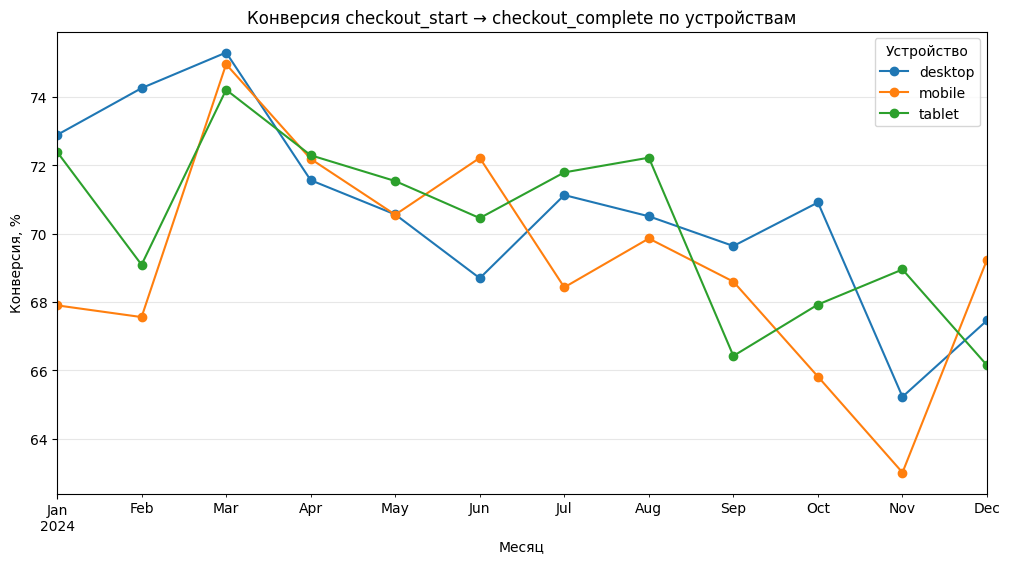

In [31]:
# Посмотрим, на каких устройствах и ОС конверсия checkout_start → checkout_complete хуже всего
# (Если на одной платформе, похоже на техническую ошибку)

# Оставим только два нужных шага воронки и добавим месяц
checkout_events = pa_marketplace_events[
    pa_marketplace_events['event_type'].isin(['checkout_start', 'checkout_complete'])
].copy()
checkout_events['month'] = pd.to_datetime(checkout_events['event_date']).dt.to_period('M')

# Конверсия по месяцам в разрезе устройств
checkout_by_device = checkout_events.pivot_table(
    index=['month', 'device'],
    columns='event_type',
    values='user_id',
    aggfunc='nunique'
)
checkout_by_device['conversion'] = (
    checkout_by_device['checkout_complete'] / checkout_by_device['checkout_start'] * 100
)

ax = checkout_by_device['conversion'].unstack('device').plot(kind='line', marker='o', figsize=(12, 6))
plt.title('Конверсия checkout_start → checkout_complete по устройствам')
plt.xlabel('Месяц')
plt.ylabel('Конверсия, %')
plt.legend(title='Устройство')
plt.grid(alpha=0.3)
plt.show()

In [32]:
# Посмотрим на LTV в разрезе каналов

# Посчитаем выручку по когортам, каналам привлечения и n_month, и отсортируем её в нужном порядке для расчёта накопленной выручки
cohort_rev = (pa_marketplace_orders
    .groupby(['acq_channel', 'cohort_month', 'n_month'])['revenue']
    .sum()
    .reset_index()
    .sort_values(by=['acq_channel', 'cohort_month', 'n_month'])
             )

# Посчитаем накопленную выручку
cohort_rev['cum_revenue'] = cohort_rev.groupby(['acq_channel', 'cohort_month'])['revenue'].cumsum()

# Посчитаем размеры каждой когорты
cohort_size = (pa_marketplace_orders
    .groupby(['acq_channel', 'cohort_month'])['user_id']
    .nunique()
    .reset_index(name='cohort_size')
              )

# Объединим накопленную выручку и размеры когорты
ltv_df = pd.merge(cohort_rev, cohort_size, on=['acq_channel', 'cohort_month'], how='inner')

# Посчитаем LTV
ltv_df['LTV'] = ltv_df['cum_revenue'] / ltv_df['cohort_size']

display(ltv_df.head())

,acq_channel,cohort_month,n_month,revenue,cum_revenue,cohort_size,LTV
0,Affiliate,2024-01-01,0.0,151314.1860,151314.1860,204,741.736206
1,Affiliate,2024-01-01,1.0,221207.1610,372521.3470,204,1826.085034
2,Affiliate,2024-01-01,2.0,108931.2820,481452.6290,204,2360.061907
3,Affiliate,2024-01-01,3.0,38450.7170,519903.3460,204,2548.545814
4,Affiliate,2024-01-01,4.0,25742.0665,545645.4125,204,2674.732414


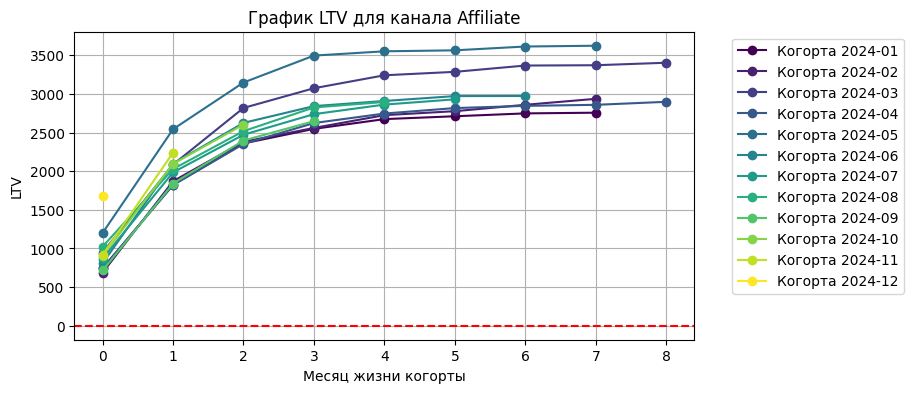

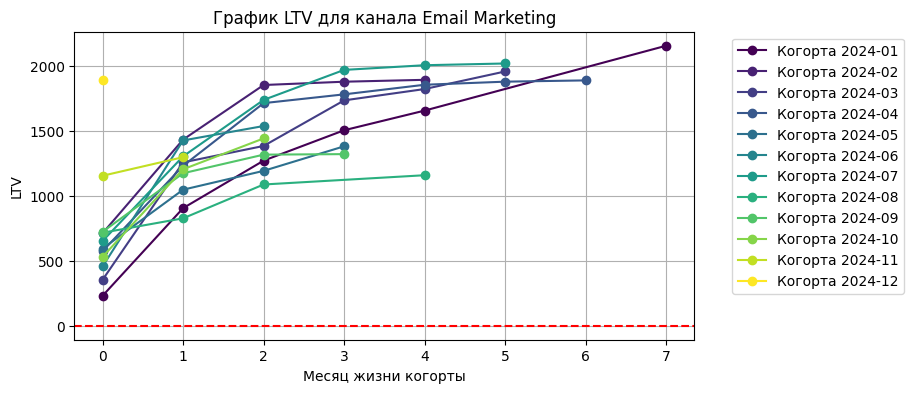

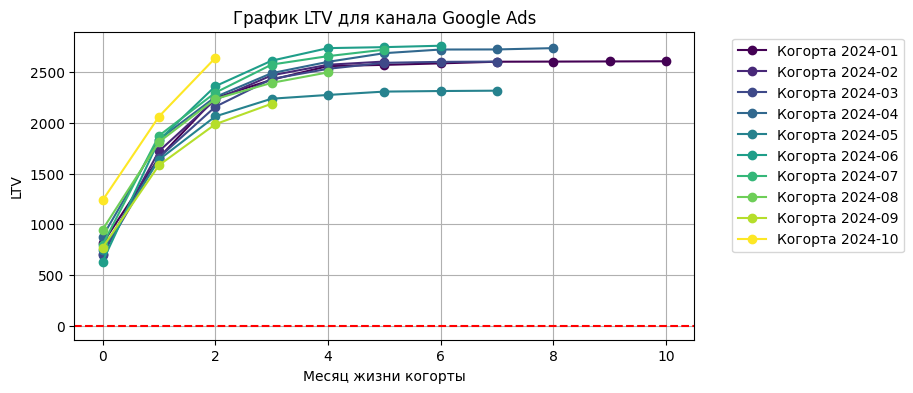

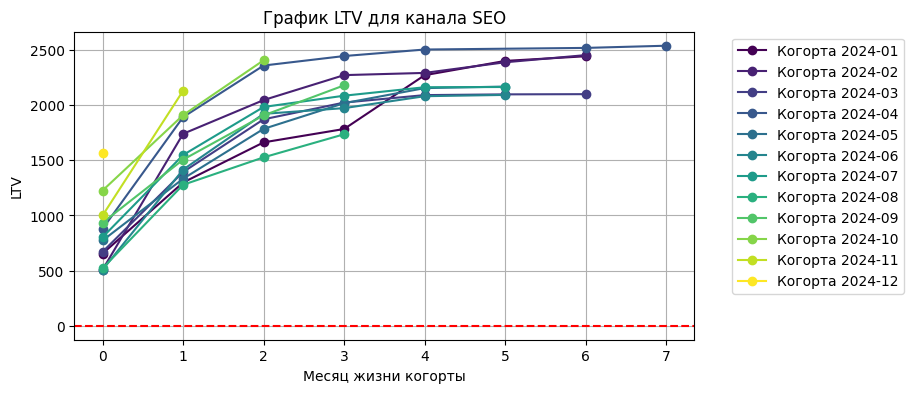

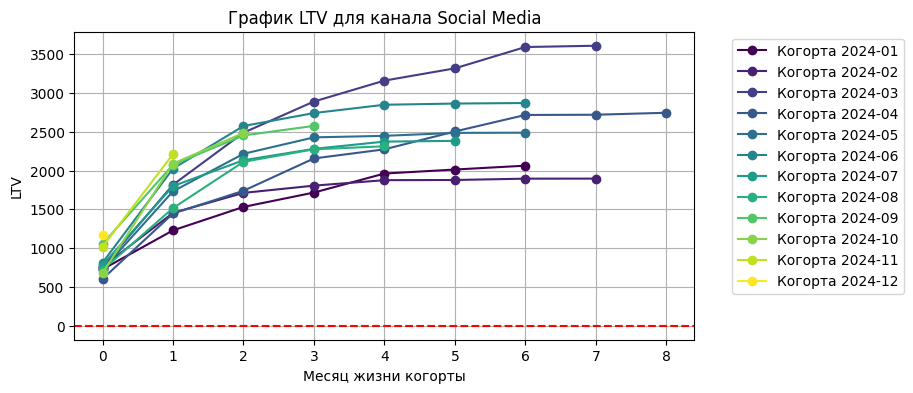

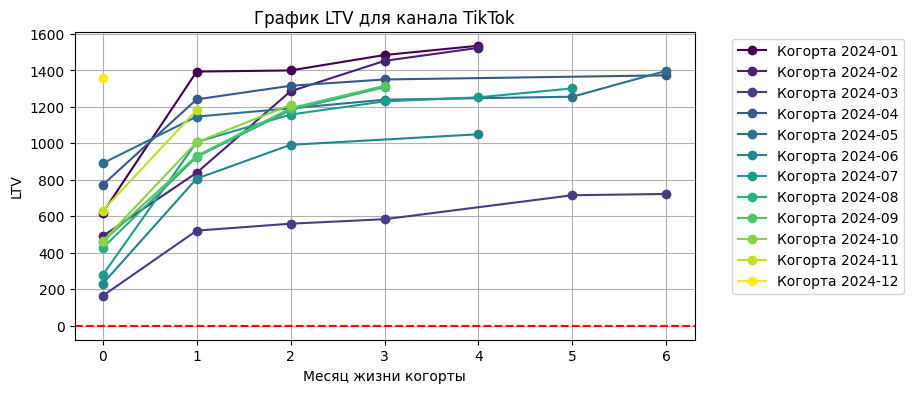

In [33]:
# Построим графики LTV в разрезе каналов
for channel in ltv_df['acq_channel'].unique():
    plt.subplots(figsize=(8,4))
    df_plot = ltv_df[ltv_df['acq_channel'] == channel]

    cohorts = sorted(df_plot['cohort_month'].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, len(cohorts)))
    
    for i, month in enumerate(cohorts):
        df_plot2 = df_plot[df_plot['cohort_month'] == month]
        month_label = pd.Timestamp(month).strftime('%Y-%m')
        plt.plot(df_plot2['n_month'], df_plot2['LTV'], color=colors[i], marker='o', label=f'Когорта {month_label}')
        
    plt.axhline(y=0, linestyle='--', color='red')
    plt.title(f'График LTV для канала {channel}')
    plt.xlabel('Месяц жизни когорты')
    plt.ylabel('LTV')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()
    plt.show() 

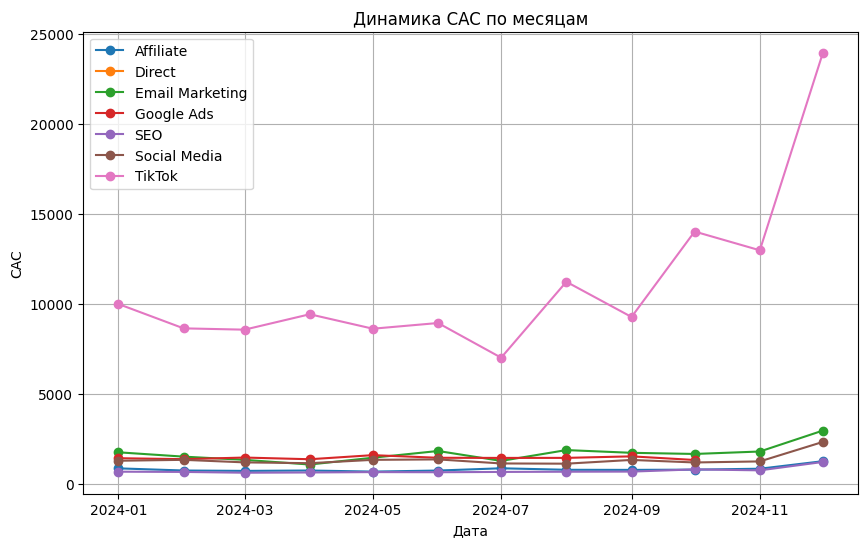

In [34]:
# Посмотрим на CAC в разрезе каналов

# Отфильтруем таблицу pa_marketplace_users: оставляем только платящих клиентов
unique_order_users = pa_marketplace_orders['user_id'].unique()
users_filtered = pa_marketplace_users[pa_marketplace_users['user_id'].isin(unique_order_users)]

# Считаем количество покупателей в каждом канале привлечения
users_groupped = users_filtered.groupby(['cohort_month', 'acq_channel'])['user_id'].nunique().reset_index(name='unique_users_count')

# Объединяем датасеты по каналу привлечения и когорте
user_base = pd.merge(pa_marketplace_campaign_costs, users_groupped, left_on=['acq_channel', 'spend_month'], right_on=['acq_channel', 'cohort_month'], how='left')
user_base['unique_users_count'] = user_base['unique_users_count'].fillna(0)

# Суммируем количество клиентов и затраты за месяц
cac_df = user_base.groupby(['acq_channel', 'spend_month']).agg(
    cost=('budget', 'sum'),
    users_count=('unique_users_count', 'sum')
).reset_index()

# Cчитаем CAC
cac_df['CAC'] = cac_df['cost'] / cac_df['users_count']

# Построим график динамики CAC по месяцам
plt.figure(figsize=(10,6))
for channel in cac_df['acq_channel'].unique():
    df_plot = cac_df[cac_df['acq_channel'] == channel]
    plt.plot(df_plot['spend_month'], df_plot['CAC'], label=channel, marker='o')
    
plt.title('Динамика CAC по месяцам')
plt.xlabel('Дата')
plt.ylabel('CAC')
plt.grid()
plt.legend()
plt.show()

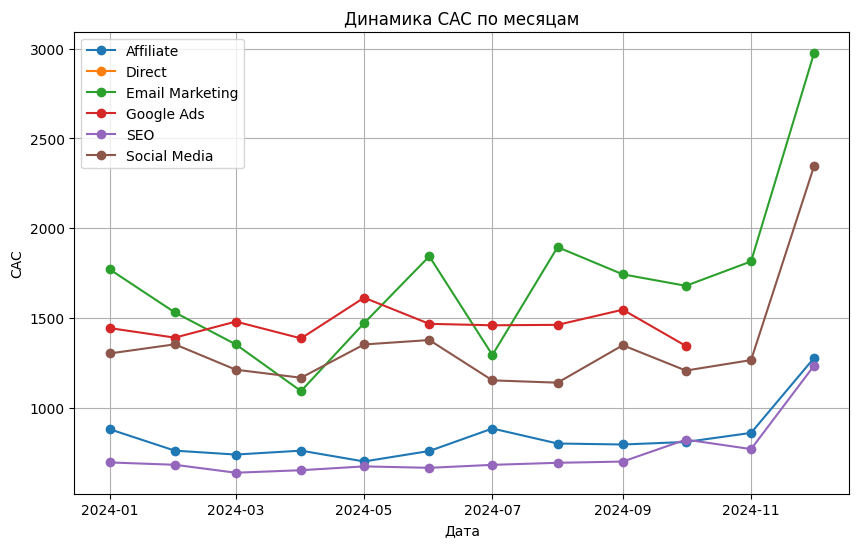

In [35]:
# TikTok очень выбивается из сумм других источников
# Построим график динамики CAC по месяцам без учёта TikTok, чтобы ярче увидеть различие стоимости других источников
plt.figure(figsize=(10,6))
no_tiktok = cac_df[cac_df['acq_channel'] != 'TikTok']['acq_channel']
for channel in no_tiktok.unique():
    df_plot = cac_df[cac_df['acq_channel'] == channel]
    plt.plot(df_plot['spend_month'], df_plot['CAC'], label=channel, marker='o')

plt.title('Динамика CAC по месяцам')
plt.xlabel('Дата')
plt.ylabel('CAC')
plt.grid()
plt.legend() 
plt.show()

In [36]:
# Посмотрим на ROI - Return on Investment - в разрезе каналов

# Объединим таблицы с CAC и LTV
roi_df = pd.merge(cac_df[['acq_channel', 'spend_month', 'CAC']], 
                  ltv_df[['acq_channel', 'cohort_month', 'n_month', 'LTV']],
                  left_on=['acq_channel', 'spend_month'],
                  right_on=['acq_channel', 'cohort_month'],
                  how='inner')

# Посчитаем ROI 
roi_df['ROI'] = (roi_df['LTV'] - roi_df['CAC']) / roi_df['CAC'] * 100

display(roi_df.head())

,acq_channel,spend_month,CAC,cohort_month,n_month,LTV,ROI
0,Affiliate,2024-01-01,879.134252,2024-01-01,0.0,741.736206,-15.628790
1,Affiliate,2024-01-01,879.134252,2024-01-01,1.0,1826.085034,107.714013
2,Affiliate,2024-01-01,879.134252,2024-01-01,2.0,2360.061907,168.452958
3,Affiliate,2024-01-01,879.134252,2024-01-01,3.0,2548.545814,189.892676
4,Affiliate,2024-01-01,879.134252,2024-01-01,4.0,2674.732414,204.246184


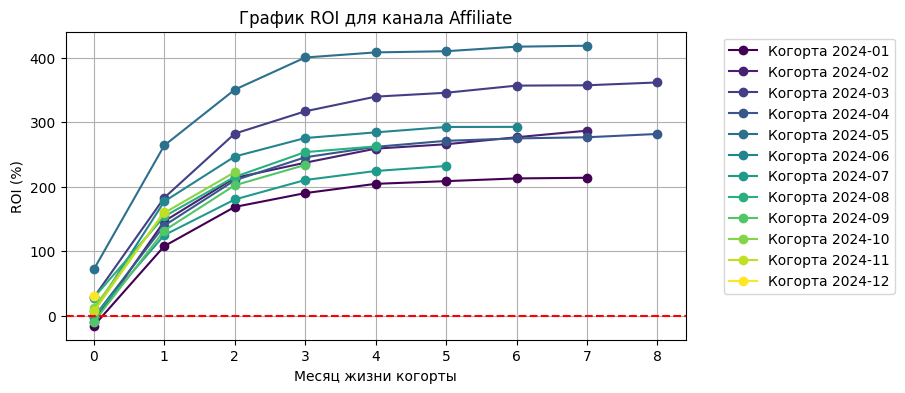

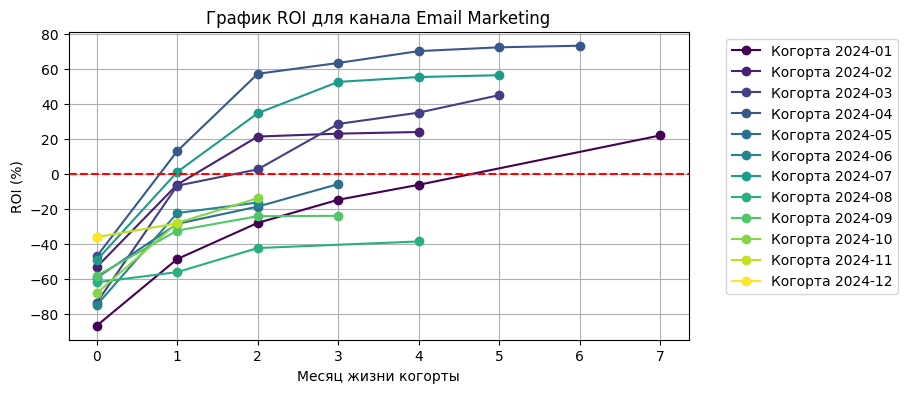

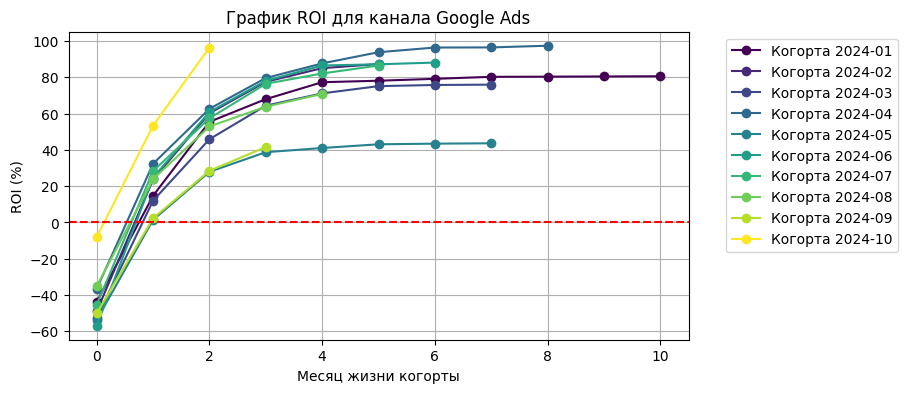

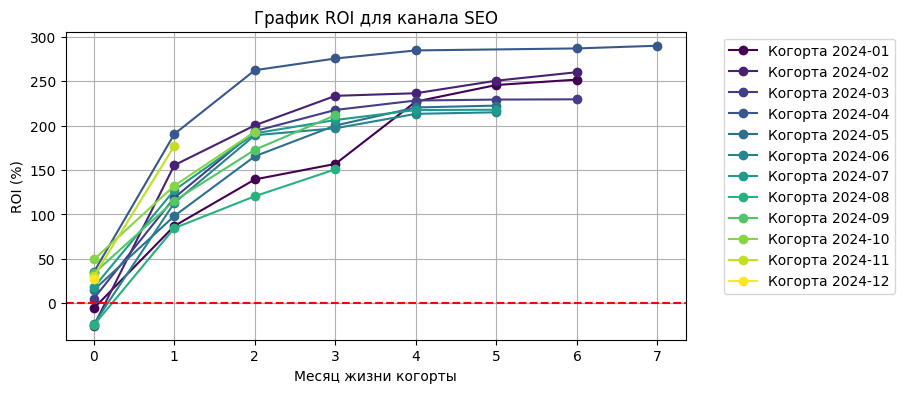

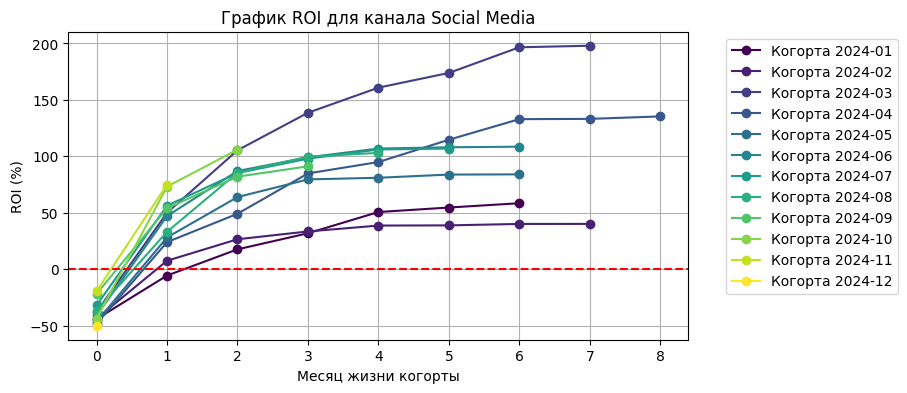

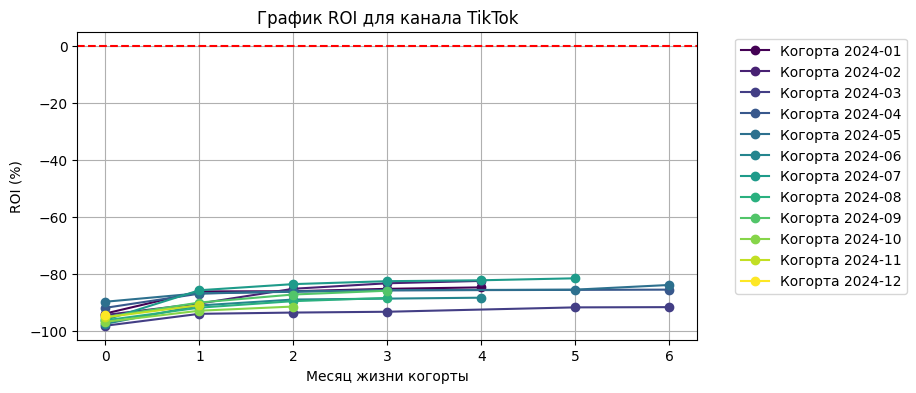

In [37]:
# Построим графики ROI 
for channel in roi_df['acq_channel'].unique():
    plt.subplots(figsize=(8,4))
    df_plot = roi_df[roi_df['acq_channel'] == channel]

    cohorts = sorted(df_plot['cohort_month'].unique())
    colors = plt.cm.viridis(np.linspace(0, 1, len(cohorts)))
    
    for i, month in enumerate(cohorts):
        df_plot2 = df_plot[df_plot['cohort_month'] == month]
        month_label = pd.Timestamp(month).strftime('%Y-%m')
        plt.plot(df_plot2['n_month'], df_plot2['ROI'], color=colors[i], marker='o', label=f'Когорта {month_label}')
        
    plt.axhline(y=0, linestyle='--', color='red')
    plt.title(f'График ROI для канала {channel}')
    plt.xlabel('Месяц жизни когорты')
    plt.ylabel('ROI (%)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()
    plt.show()    

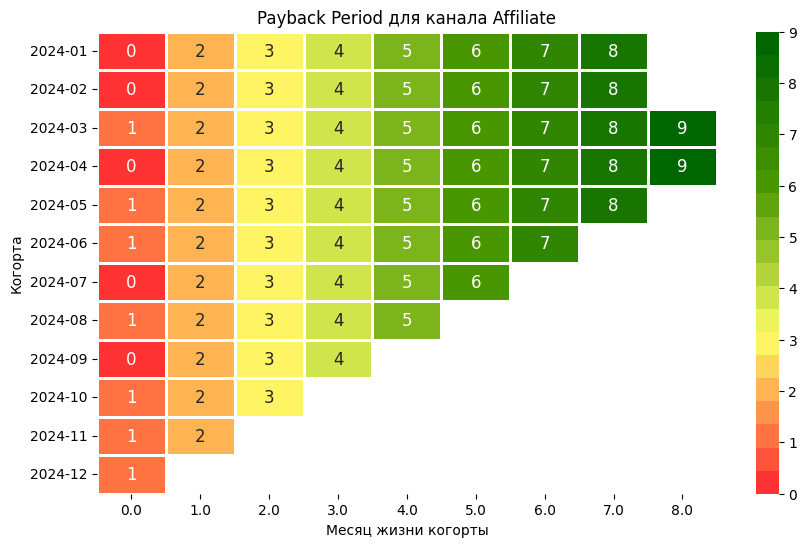

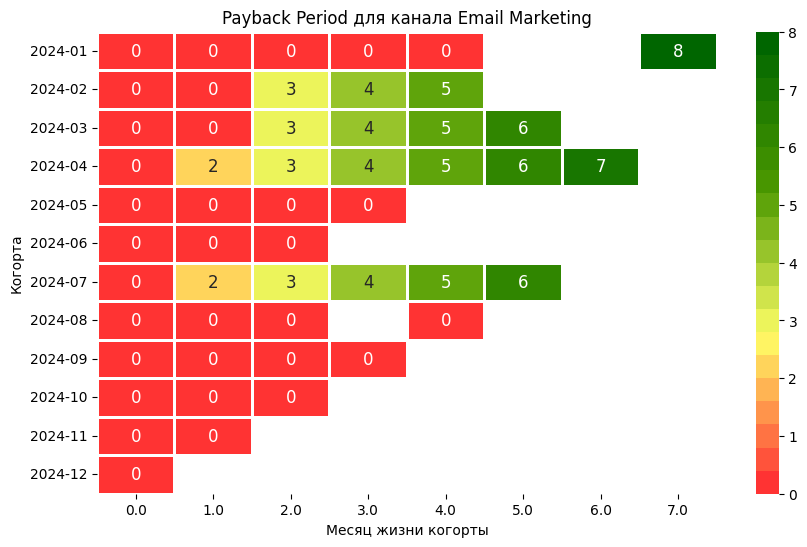

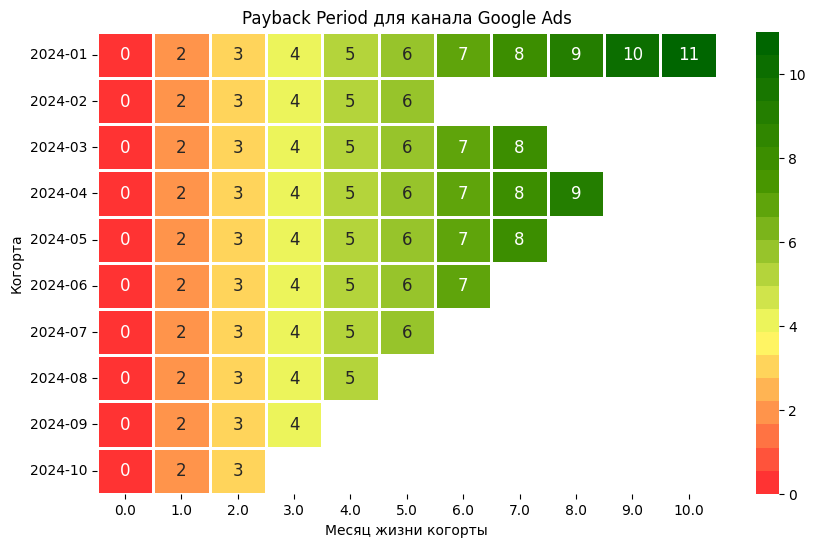

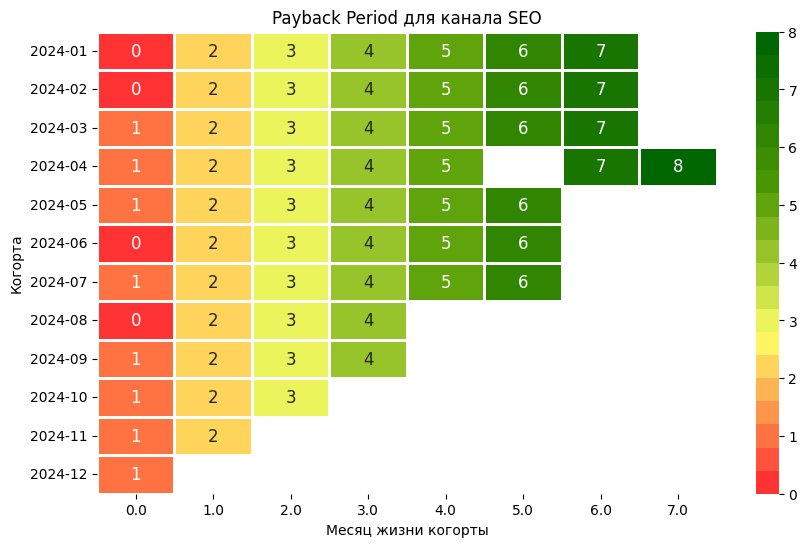

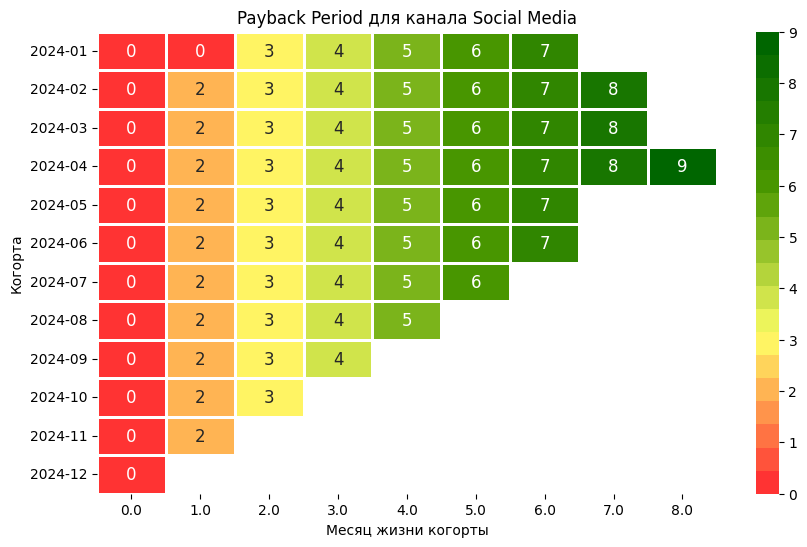

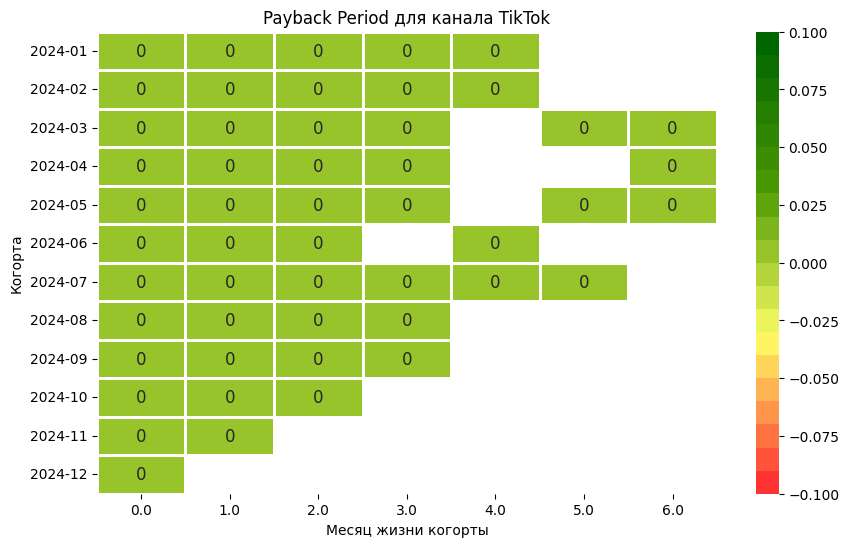

In [38]:
# Посмотрим на Payback Period в разрезе каналов

# Назначим цвета для тепловой карты
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900', '#006600'], N=20)

# Построим тепловые карты для каждого канала
for channel in roi_df['acq_channel'].unique():
    # Оставляем данные только одного канала
    df_channel = roi_df[roi_df['acq_channel'] == channel].copy()
    # Рассчитываем payback period
    df_channel['Payback_Period'] = df_channel.apply(lambda row: row['n_month'] + 1 if row['LTV'] >= row['CAC'] else 0, axis=1)

    # Пивотируем данные
    pp_pivot = df_channel.pivot(index='cohort_month', columns='n_month', values='Payback_Period')
    pp_pivot.index = pp_pivot.index.strftime('%Y-%m')

    # Строим графики
    plt.figure(figsize=(10,6))
    sns.heatmap(pp_pivot, cmap=cmap, annot=True, fmt='.0f', linewidth=2, annot_kws={'size': 12})
    plt.title(f'Payback Period для канала {channel}')
    plt.xlabel('Месяц жизни когорты')
    plt.ylabel('Когорта')
    plt.show()

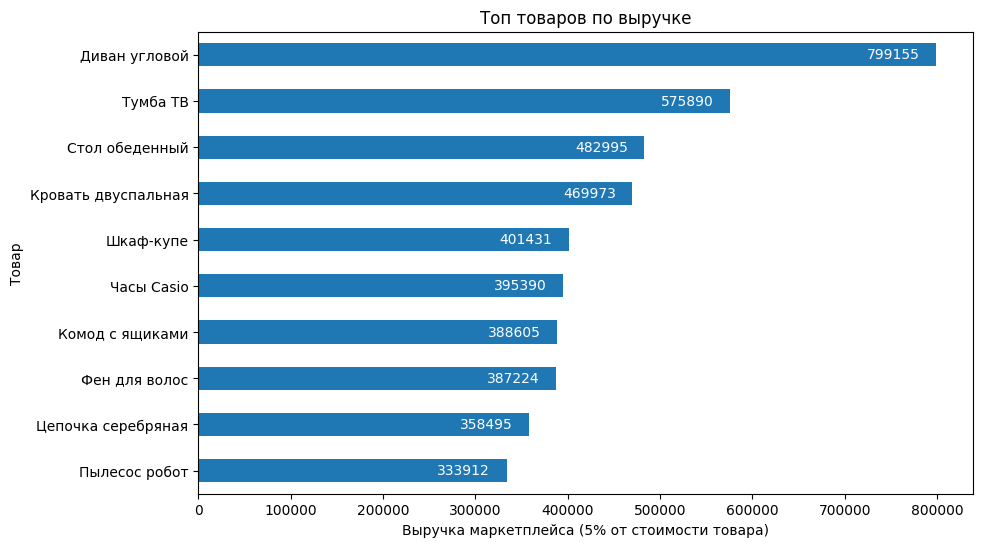

In [39]:
# Посмотрим на топ товаров по выручке
products_revenue = (
        pa_marketplace_orders
        .groupby('product_name')['revenue']
        .sum()
        .reset_index(name='total_revenue')
        .sort_values(by='total_revenue', ascending=False)
        )

# Построим диаграмму для удобства чтения
ax = products_revenue.head(10).sort_values(by='total_revenue', ascending=True).plot(
    kind='barh', 
    x='product_name', 
    y='total_revenue', 
    figsize=(10,6),
    legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-50, color='white')
plt.title('Топ товаров по выручке')
plt.xlabel('Выручка маркетплейса (5% от стоимости товара)')
plt.ylabel('Товар')
plt.show()

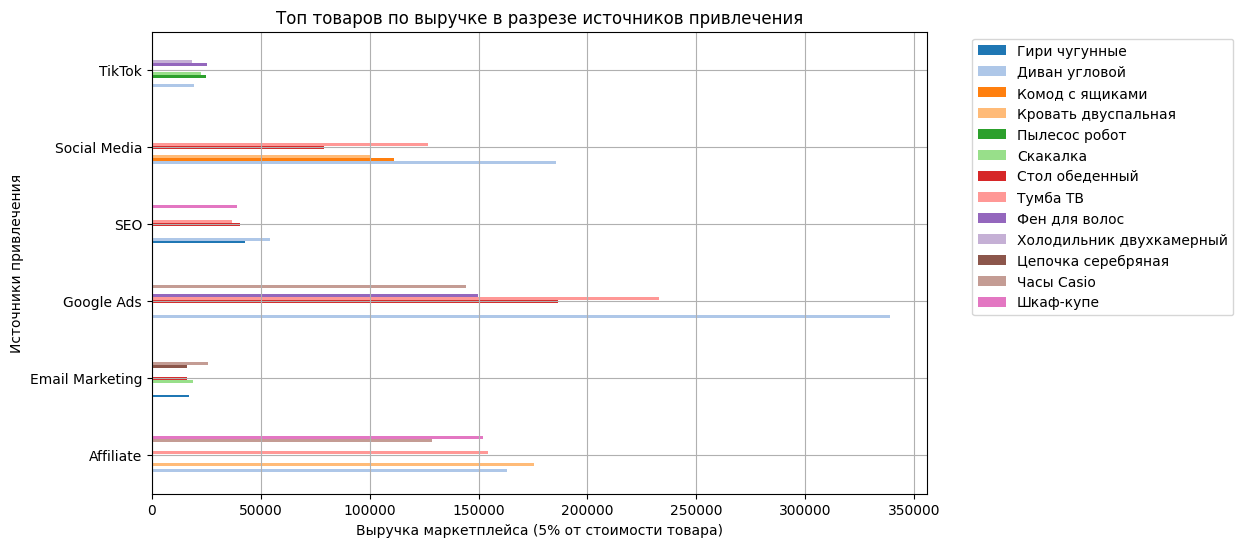

In [40]:
# Посмотрим на топ товаров по выручке в разрезе источников привлечения
products_revenue_by_channel = (
        pa_marketplace_orders
        .groupby(['acq_channel', 'product_name'])['revenue']
        .sum()
        .reset_index(name='total_revenue')
        .sort_values(by='total_revenue', ascending=False)
        .groupby('acq_channel')
        .head(5)
        .sort_values(by=['acq_channel', 'total_revenue'], ascending=False)
        )

# Пивотируем данные, чтобы постоить диаграмму
revenue_by_channel_pivot = products_revenue_by_channel.pivot(index='acq_channel', columns='product_name', values='total_revenue')

# Построим диаграмму для удобства чтения
colors = plt.cm.tab20(range(len(products_revenue_by_channel)))
revenue_by_channel_pivot.plot(kind='barh', label='acq_channel', figsize=(10,6), color=colors)
plt.title('Топ товаров по выручке в разрезе источников привлечения')
plt.xlabel('Выручка маркетплейса (5% от стоимости товара)')
plt.ylabel('Источники привлечения')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

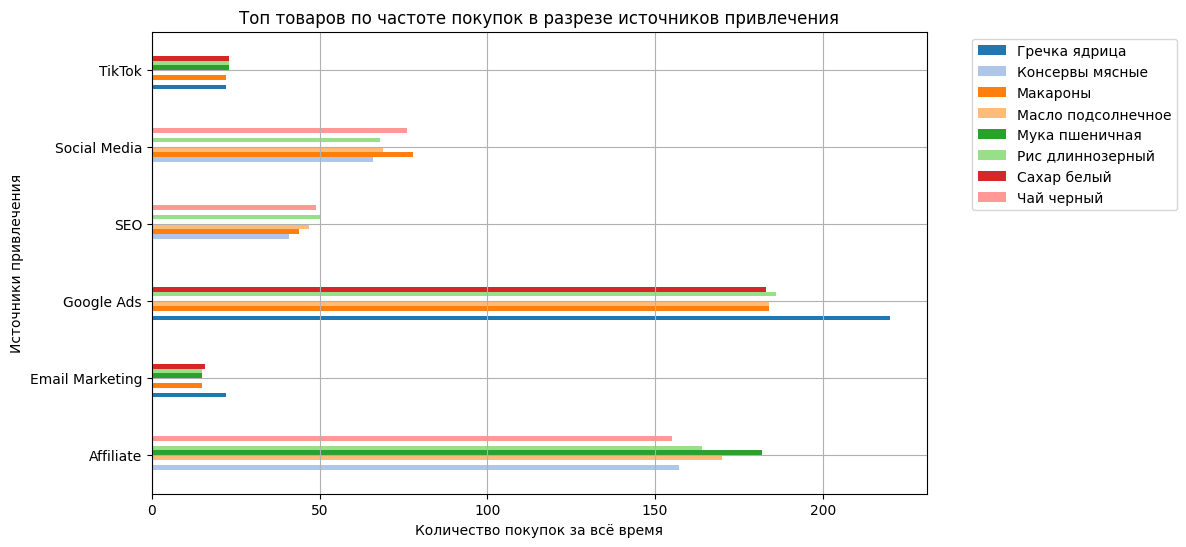

In [41]:
# Посмотрим на топ товаров по частоте покупок в разрезе источников привлечения
popular_products_by_channel = (
        pa_marketplace_orders
        .groupby(['acq_channel', 'product_name'])['order_id']
        .nunique()
        .reset_index(name='orders_count')
        .sort_values(by='orders_count', ascending=False)
        .groupby('acq_channel')
        .head(5)
        .sort_values(by=['acq_channel', 'orders_count'], ascending=False)
        )

# Пивотируем данные, чтобы постоить диаграмму
popular_products_by_channel_pivot = popular_products_by_channel.pivot(index='acq_channel', columns='product_name', values='orders_count')

# Построим диаграмму для удобства чтения
colors = plt.cm.tab20(range(len(popular_products_by_channel)))
popular_products_by_channel_pivot.plot(kind='barh', label='acq_channel', figsize=(10,6), color=colors)
plt.title('Топ товаров по частоте покупок в разрезе источников привлечения')
plt.xlabel('Количество покупок за всё время')
plt.ylabel('Источники привлечения')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.show()

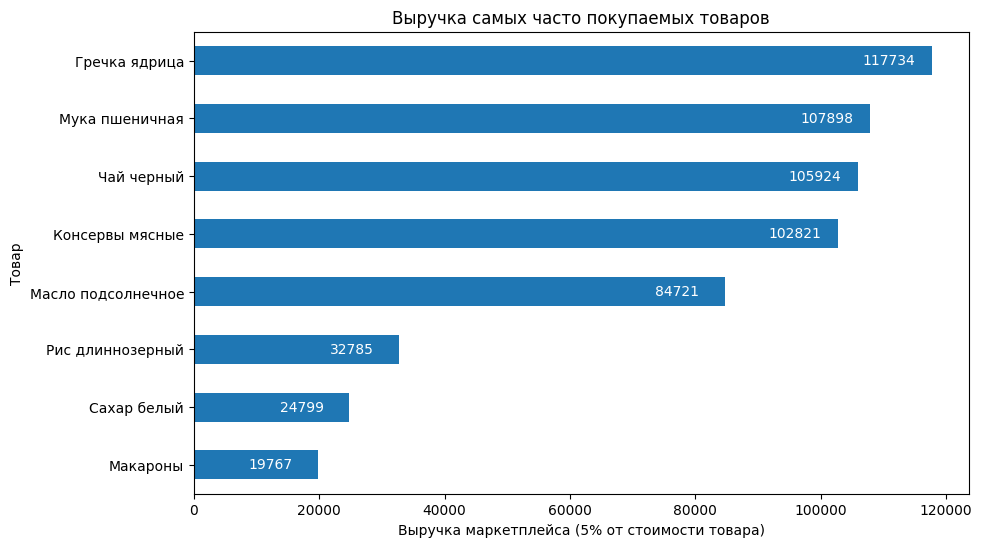

In [42]:
# Посмотрим, приносят ли большую прибыль самые покупаемые товары
popular_products_df = pa_marketplace_orders[pa_marketplace_orders['product_name'].isin(popular_products_by_channel['product_name'])]

popular_products_revenue = (
    popular_products_df
    .groupby('product_name')['revenue']
    .sum()
    .reset_index(name='total_revenue')
    .sort_values(by='total_revenue', ascending=False)
    )

# Построим диаграмму для удобства чтения
ax = popular_products_revenue.sort_values(by='total_revenue', ascending=True).plot(
    kind='barh', 
    x='product_name', 
    y='total_revenue', 
    figsize=(10,6),
    legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-50, color='white')
plt.title('Выручка самых часто покупаемых товаров')
plt.xlabel('Выручка маркетплейса (5% от стоимости товара)')
plt.ylabel('Товар')
plt.show()

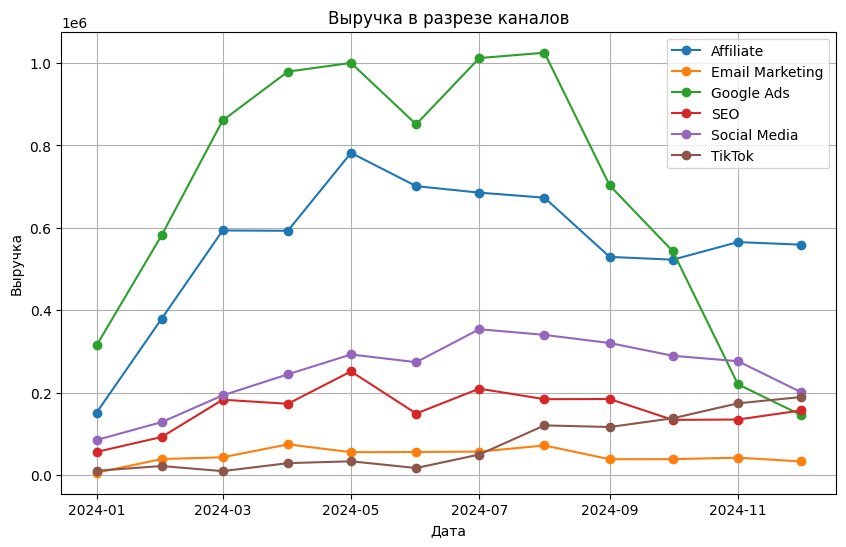

In [43]:
# Посмотрим на выручку по источникам в целом
revenue_by_channel = pa_marketplace_orders.groupby(['order_month', 'acq_channel'])['revenue'].sum().reset_index(name='total_revenue')
revenue_by_channel = revenue_by_channel.sort_values(by=['acq_channel', 'order_month'])

# Построим график
plt.figure(figsize=(10,6))
for channel in revenue_by_channel['acq_channel'].unique():
    df_plot = revenue_by_channel[revenue_by_channel['acq_channel'] == channel]
    plt.plot(df_plot['order_month'], df_plot['total_revenue'], label=channel, marker='o')
    
plt.title('Выручка в разрезе каналов')
plt.xlabel('Дата')
plt.ylabel('Выручка')
plt.grid()
plt.legend()
plt.show()                                                                                                   

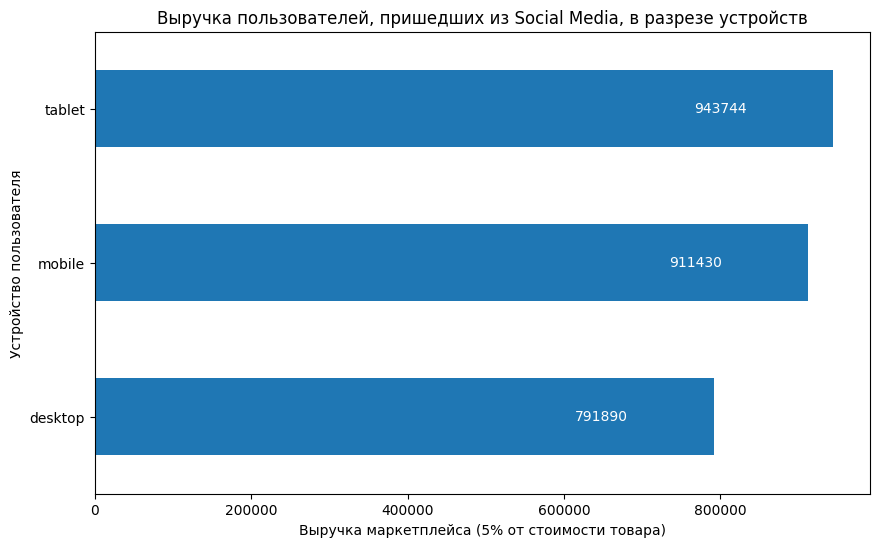

In [44]:
# Изучим самый неоднозначный канал Social Media и посмотрим, как можно улучшить его показатели
# Посмотрим на то, как отличаются пользователи, пришедшие из этого канала, в разрезе устройств 

# Добавим в таблицу orders устройство пользователя
user_device_no_duplicates = pa_marketplace_events.drop_duplicates(subset=['user_id', 'device'])
pa_marketplace_orders = pd.merge(pa_marketplace_orders, user_device_no_duplicates[['user_id', 'device']], on='user_id', how='left')

# Сгруппируем по устройствам и посчитаем выручку
revenue_by_device_social_media = (
    pa_marketplace_orders[pa_marketplace_orders['acq_channel'] == 'Social Media']
        .groupby('device')['revenue']
        .sum()
        .reset_index(name='total_revenue')
    )

# Построим диаграмму
ax = revenue_by_device_social_media.sort_values(by='total_revenue', ascending=True).plot(
    kind='barh', 
    x='device', 
    y='total_revenue', 
    figsize=(10,6),
    legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-100, color='white')
plt.title('Выручка пользователей, пришедших из Social Media, в разрезе устройств')
plt.xlabel('Выручка маркетплейса (5% от стоимости товара)')
plt.ylabel('Устройство пользователя')
plt.show()

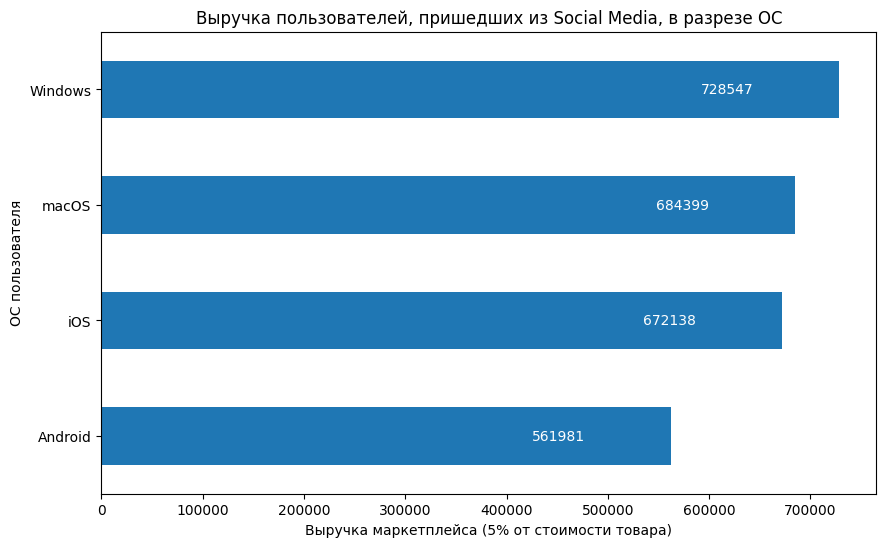

In [45]:
# Теперь посмотрим на тех же пользователей в разрезе операционных систем

# Добавим в таблицу orders устройство пользователя
user_os_no_duplicates = pa_marketplace_events.drop_duplicates(subset=['user_id', 'os'])
pa_marketplace_orders = pd.merge(pa_marketplace_orders, user_os_no_duplicates[['user_id', 'os']], on='user_id', how='left')

# Сгруппируем по устройствам и посчитаем выручку
revenue_by_os_social_media = (
    pa_marketplace_orders[pa_marketplace_orders['acq_channel'] == 'Social Media']
        .groupby('os')['revenue']
        .sum()
        .reset_index(name='total_revenue')
    )

# Построим диаграмму
ax = revenue_by_os_social_media.sort_values(by='total_revenue', ascending=True).plot(
    kind='barh', 
    x='os', 
    y='total_revenue', 
    figsize=(10,6),
    legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-100, color='white')
plt.title('Выручка пользователей, пришедших из Social Media, в разрезе ОС')
plt.xlabel('Выручка маркетплейса (5% от стоимости товара)')
plt.ylabel('ОС пользователя')
plt.show()

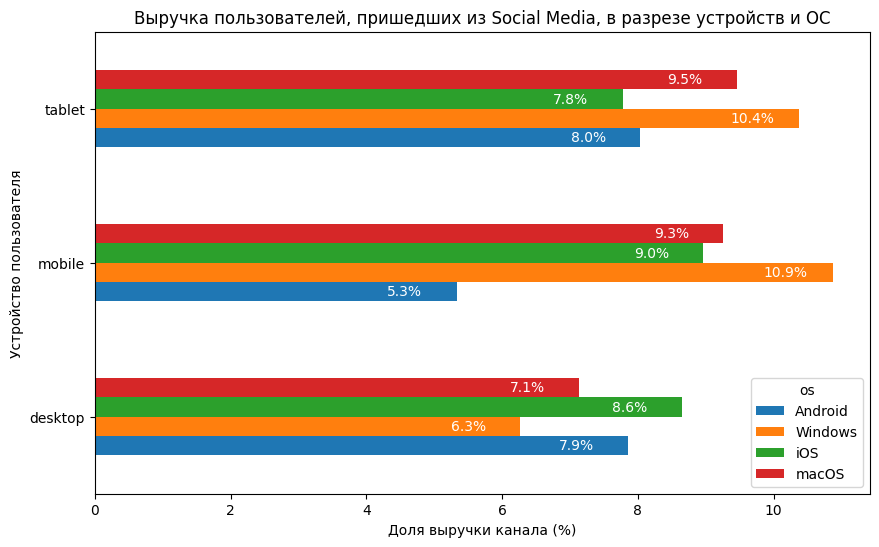

In [46]:
# Посмотрим на выручку этих же пользователей в разрезе и устройства, и ОС

# Сгруппируем по устройству и ОС и посчитаем выручку
revenue_by_device_os_social_media = (
    pa_marketplace_orders[pa_marketplace_orders['acq_channel'] == 'Social Media']
        .groupby(['device', 'os'])['revenue']
        .sum()
        .reset_index(name='total_revenue')
    )

# Пивотируем данные
revenue_by_device_os_social_media_pivot = revenue_by_device_os_social_media.pivot(index='device', columns='os', values='total_revenue').fillna(0)

revenue_pct = revenue_by_device_os_social_media_pivot / revenue_by_device_os_social_media_pivot.sum().sum() * 100

# Построим диаграмму
ax = revenue_pct.plot(
    kind='barh',  
    figsize=(10,6),
    legend=True)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=-50, color='white')
plt.title('Выручка пользователей, пришедших из Social Media, в разрезе устройств и ОС')
plt.xlabel('Доля выручки канала (%)')
plt.ylabel('Устройство пользователя')
plt.show()

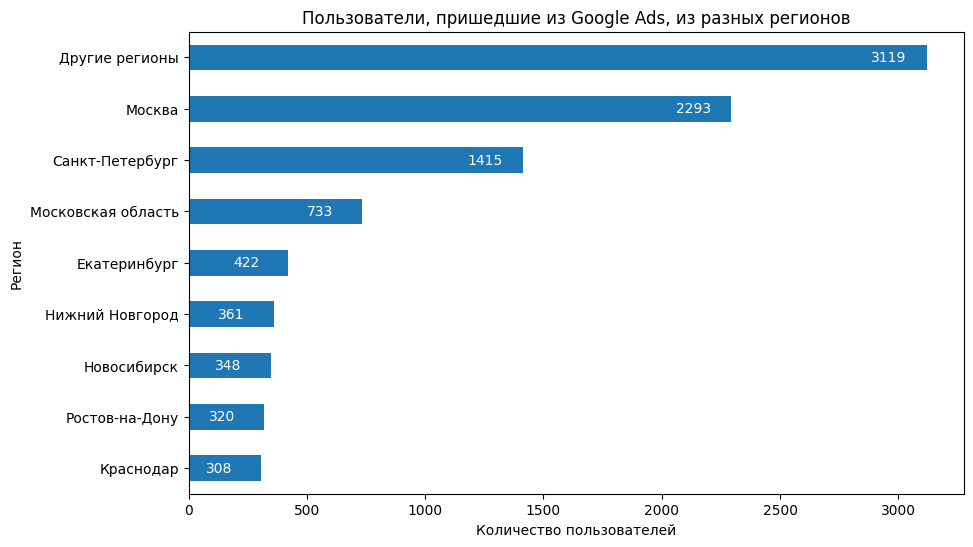

In [47]:
# Посмотрим на канал с самой высокой выручкой - Google Ads
# Его легко масштабировать, но для этого нужно изучить, на какие сегменты аудитории сделать упор (география, устройство, ОС, возраст)

# pa_marketplace_orders = pd.merge(pa_marketplace_orders, pa_marketplace_users[['user_id', 'region', 'age']])

# Сгруппируем по региону и посчитаем количество пользователей
user_regions_google_ads = (
    pa_marketplace_users[pa_marketplace_users['acq_channel'] == 'Google Ads']
        .groupby('region')['user_id']
        .count()
        .reset_index(name='users_count')
    )

# Построим диаграмму
ax = user_regions_google_ads.sort_values(by='users_count', ascending=True).plot(
    kind='barh', 
    x='region', 
    y='users_count', 
    figsize=(10,6),
    legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-40, color='white')
plt.title('Пользователи, пришедшие из Google Ads, из разных регионов')
plt.xlabel('Количество пользователей')
plt.ylabel('Регион')
plt.show()

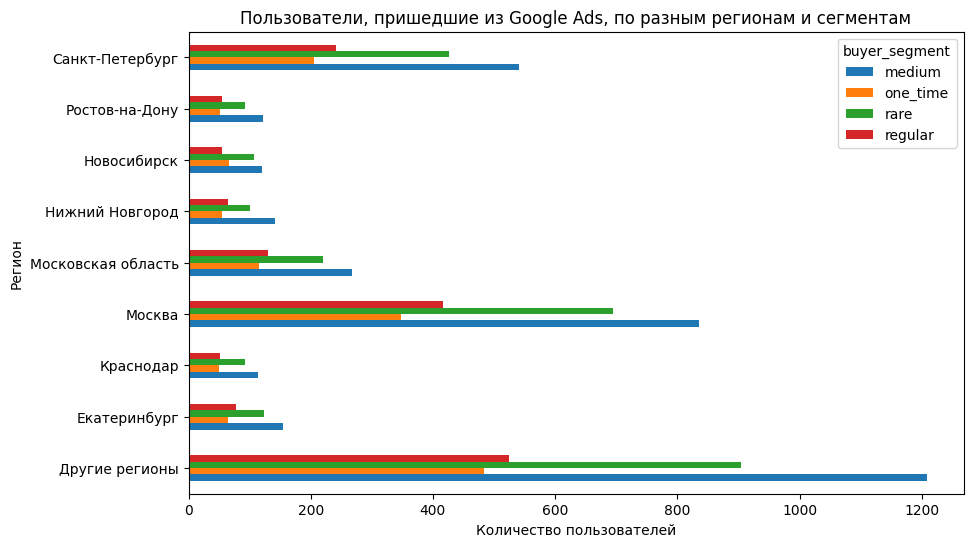

In [48]:
# Посмотрим на связь региона и сегмента покупателя

# Сначала посмотрим на количество пользователей из этого канала привлечения в разных регионах и разных сегментах
region_segment_google_ads = (
    pa_marketplace_users[pa_marketplace_users['acq_channel'] == 'Google Ads']
    .groupby(['region', 'buyer_segment'])['user_id']
    .count()
    .reset_index(name='users_count')
    )

# Пивотируем данные
region_segment_google_ads_pivot = region_segment_google_ads.pivot(index='region', columns='buyer_segment', values='users_count')

# Построим диаграмму
ax = region_segment_google_ads_pivot.plot(
    kind='barh',  
    figsize=(10,6),
    legend=True)
plt.title('Пользователи, пришедшие из Google Ads, по разным регионам и сегментам')
plt.xlabel('Количество пользователей')
plt.ylabel('Регион')
plt.show()

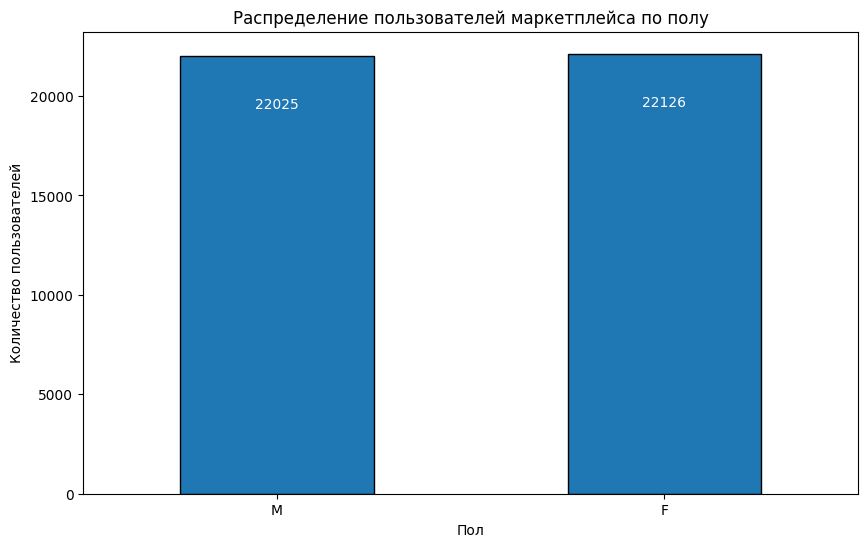

In [49]:
# Посмотрим, покупатели какого пола превалируют в продукте в целом
users_gender = pa_marketplace_users.groupby('gender')['user_id'].count().reset_index(name='users_count')

# Построим диаграмму
ax = users_gender.sort_values(by='users_count', ascending=True).plot(
    kind='bar', 
    x='gender', 
    y='users_count', 
    figsize=(10,6),
    edgecolor='black',
    legend=False,
    rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=-40, color='white')
plt.title('Распределение пользователей маркетплейса по полу')
plt.xlabel('Пол')
plt.ylabel('Количество пользователей')
plt.show()

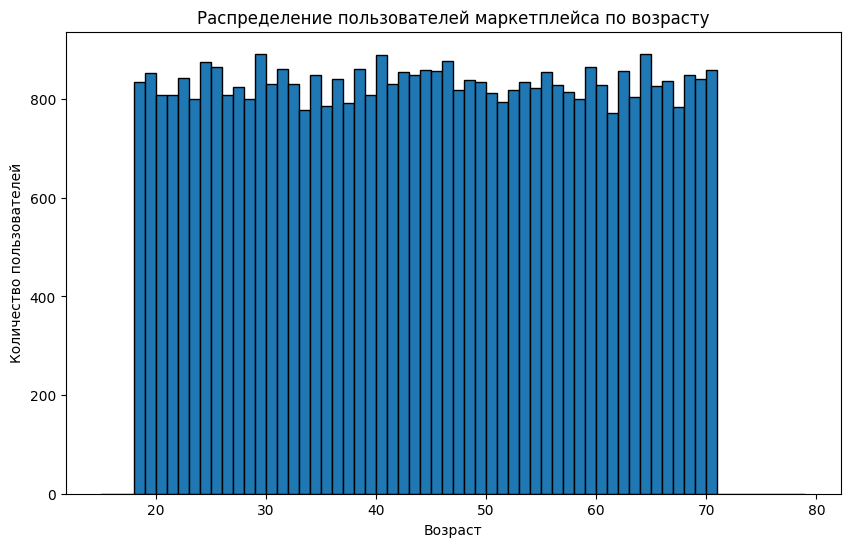

In [50]:
# Посмотрим, как распределяется возраст пользователей маркетплейса

# Построим диаграмму
ax = pa_marketplace_users['age'].plot(
    kind='hist', 
    bins=range(15, 80, 1),
    figsize=(10,6),
    edgecolor='black',
    legend=False,
    rot=0)
plt.title('Распределение пользователей маркетплейса по возрасту')
plt.xlabel('Возраст')
plt.ylabel('Количество пользователей')
plt.show()

In [55]:
print('Минимальный возраст среди пользователей: ', pa_marketplace_users['age'].min())
print('Максимальный возраст среди пользователей: ', pa_marketplace_users['age'].max())

Минимальный возраст среди пользователей:  18
Максимальный возраст среди пользователей:  70


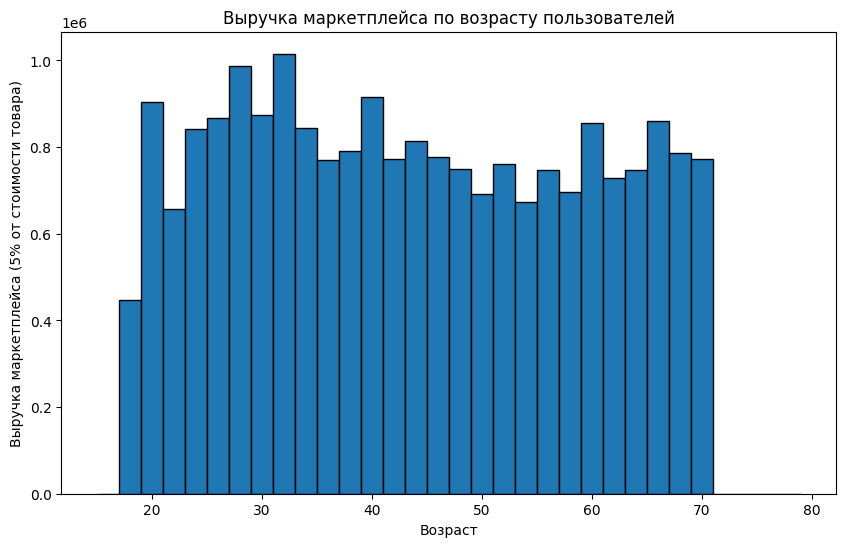

In [51]:
# Посмотрим на взаимосвязь возраста и выручки от пользователя

# Присоединим возраст к информации о заказах
pa_marketplace_orders = pd.merge(pa_marketplace_orders, pa_marketplace_users[['user_id', 'age']], on='user_id', how='left')

# Построим гистограмму
pa_marketplace_orders['age'].plot(
    kind='hist',
    bins=range(15, 80, 2),
    weights=pa_marketplace_orders['revenue'],
    figsize=(10, 6),
    edgecolor='black'
)
plt.title('Выручка маркетплейса по возрасту пользователей')
plt.xlabel('Возраст')
plt.ylabel('Выручка маркетплейса (5% от стоимости товара)')
plt.show()

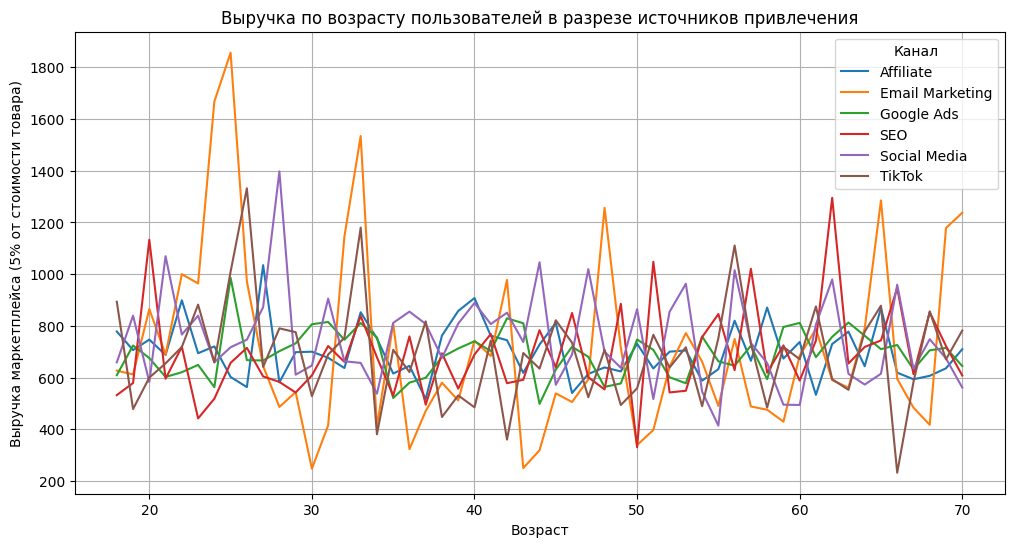

In [52]:
# Посмотрим на взаимосвязь возраста и выручки от пользователя в разрезе источников привлечения

ax = (
    pa_marketplace_orders
        .groupby(['age', 'acq_channel'])['revenue']
        .mean() # возьмём именно среднее, чтобы не зависеть от размеров групп пользователей
        .unstack()
        .plot(kind='line', figsize=(12, 6))
)
plt.title('Выручка по возрасту пользователей в разрезе источников привлечения')
plt.xlabel('Возраст')
plt.ylabel('Выручка маркетплейса (5% от стоимости товара)')
plt.legend(title='Канал')
plt.grid()
plt.show()

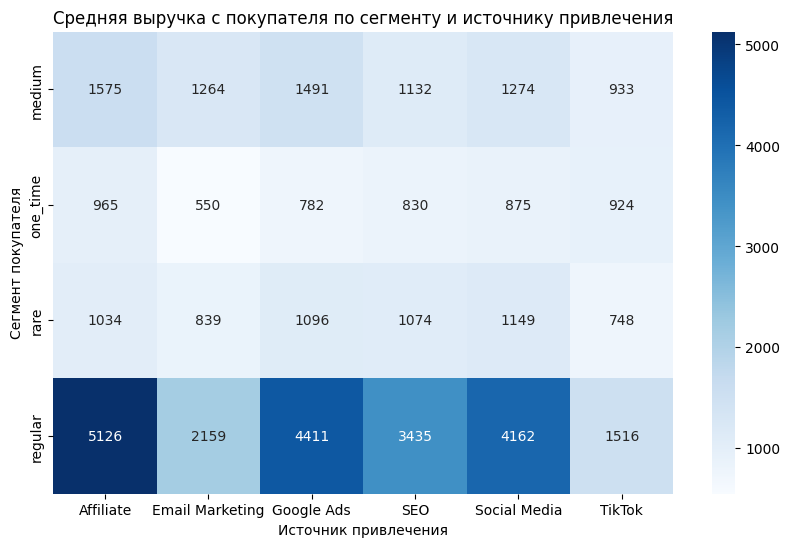

In [53]:
# Посмотрим на корреляцию выручки с покупателя, источника его привлечения и его покупательского сегмента

# Выручка с каждого покупателя
user_revenue = (
    pa_marketplace_orders
        .groupby(['user_id', 'acq_channel'])['revenue']
        .sum()
        .reset_index(name='total_revenue')
)

# Добавим сегмент покупателя
user_revenue = pd.merge(
    user_revenue,
    pa_marketplace_users[['user_id', 'buyer_segment']],
    on='user_id',
    how='left'
)

# Средняя выручка с покупателя по сегменту и каналу
revenue_by_segment_channel = user_revenue.pivot_table(
    index='buyer_segment',
    columns='acq_channel',
    values='total_revenue',
    aggfunc='mean'
)

# Построим тепловую карту
plt.figure(figsize=(10, 6))
sns.heatmap(revenue_by_segment_channel, annot=True, fmt='.0f', cmap='Blues')
plt.title('Средняя выручка с покупателя по сегменту и источнику привлечения')
plt.xlabel('Источник привлечения')
plt.ylabel('Сегмент покупателя')
plt.show()

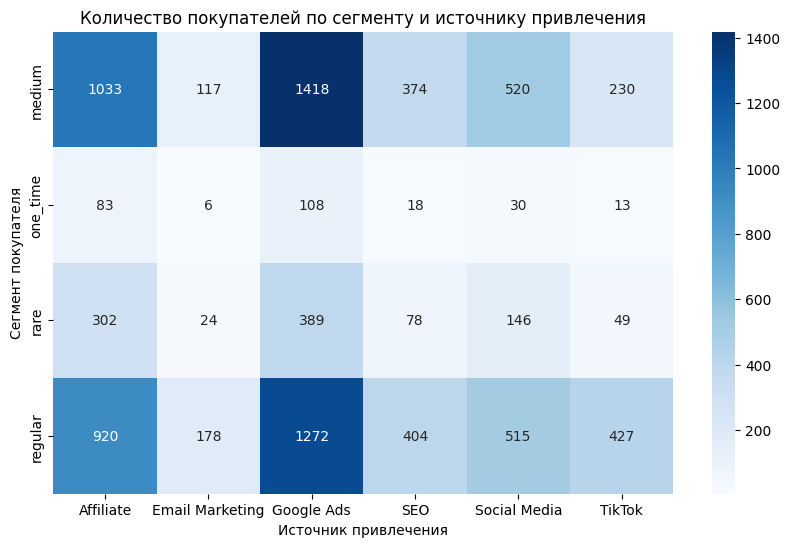

In [54]:
# Посмотрим, а сколько людей вообще относится к этим каналам и сегментам

users_by_segment_channel = user_revenue.pivot_table(
    index='buyer_segment',
    columns='acq_channel',
    values='user_id',
    aggfunc='nunique'
)

plt.figure(figsize=(10, 6))
sns.heatmap(users_by_segment_channel, annot=True, fmt='.0f', cmap='Blues')
plt.title('Количество покупателей по сегменту и источнику привлечения')
plt.xlabel('Источник привлечения')
plt.ylabel('Сегмент покупателя')
plt.show()

## Выводы по этапу 4

Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.

**Про аудиторию маркетплейса**

Пользователи продукта - это люди в возрасте от 18 до 70 лет. При этом возраст среди покупателей распределён равномерно. Чуть выделяется сегмент людей примерно от 23 до 33 лет - при таком же количестве пользователей, как и в других возрастных сегментах, он приносит немного больше выручки. Среди пользователей присутствуют и мужчины, и женщины в соотношении 50/50. 

Это значит, что реклама маркетплейса должна быть универсальной по возрасту и полу, нет какого-то конкретного сегмента, под который стоит изменять стиль рекламы.

**Как создавалась продуктовая воронка и о какой проблеме она говорит**

Я рассматривала продуктовую воронку в контексте шагов product_click → add_to_cart → checkout_start → checkout_complete. В продукте логируется намного больше событий, но другие не работают в этом анализе. 

Также я добавила туда отдельно пятый шаг, из таблицы с заказами, - order. Количество событий order отличается от количества событий checkout_complete. Это говорит о том, что либо в логировании есть какая-то ошибка, либо checkout_complete не учитывает заказы, которые были возвращены, а order учитывает.

На графике можно заметить, что в последний месяц количество событий order стало больше, чем количество событий checkout_complete. Поэтому рекомендую всё же проверить возможные ошибки логирования.

**Конверсия в продуктовой воронке**

В первой половине года конверсия была неплохой: из уникальных пользователей когорты, у которых было *любое* событие в окне 45 дней, до checkout_complete доходили около 60-65%. Но к осени эта доля упала ниже 50%.

Из выбранных этапов наиболее сильные провалы можно заметить на последних двух - checkout_start и checkout_complete. При этом в конце года по сравнению с началом конверсия на них упала в 1.2-1.4 раза:
- `checkout_start` - 80% в начале года, 65% в конце;
- `checkout_complete` - 65% в начале года, 47% в конце.

Если считать step-to-step, то переход add_to_cart → checkout_start снизился с 86% до 74%, а checkout_start → checkout_complete - с 81% до 72%.

Снижение на этапе checkout_complete может говорить о проблемах с оплатой: например, у маркетплейса нет удобных для пользователей способов оплаты, этап оплаты непонятный и сложный или только на этом этапе появляется информация о стоимости доставки, сроках и т.д.

**Окупаемость источников привлечения**

*Оставить*

Быстрее и стабильнее всего окупаются источники `Affiliate` и `SEO`: в месяц привлечения они, как правило, выходят примерно в ноль, а на второй месяц уже уверенно окупаются. Итоговый ROI у Affiliate составляет около 160-420%, а у SEO - около 150-290%. Это происходит и благодаря низкой стоимости клиента, и благодаря активности клиентов. У Affiliate также самая высокая среди других каналов средняя выручка с пользователей в сегменте regular. 

Также хорошие варианты - `Social Media` и `Google Ads`. Они окупаются ко второму месяцу. Бюджет на Google Ads нужен больше, но и выручка у него самая большая. При этом в Google Ads средняя выручка на пользователя в сегменте regular одна из самых высоких по сравнению с другими каналами. Однако Google Ads отключился в середине года из-за санкций, и, вероятно, работать с ним больше не представляется возможным.

*Пересмотреть/убрать*

`TikTok` не окупается вообще, причём у него самая высокая стоимость привлечения. Резоннее отказаться от работы с этим источником. `Email Marketing` окупается медленно и не так эффективно, как другие источники (а некоторые когорты так и не окупились), и при этом дороже, так что следует пересмотреть вложения в этот источник и, возможно, сократить их. Из графика "Выручка по возрасту пользователей в разрезе источников привлечения" видно, что неплохую выручку после прихода с канала Email Marketing приносят люди примерно 22-26 лет. Если будет решено оставить этот источник, вижу смысл сосредоточиться на работе с этим возрастным сегментом.

**Самые прибыльные товары**

8 из 10 *самых часто покупаемых* товаров относятся к категории еды, однако прибыль от них невысокая. 6 из 10 *самых прибыльных* товаров - это мебель. При этом её покупают более активно пользователи, которые пришли из источников Affiliate, Google Ads и Social Media.

**Возможные ошибки**

В таблице campaign_costs присутствует источник Direct. Прямые заходы пользователей на сайт не требуют бюджета, однако, согласно таблице, на это тратятся деньги. При этом в users нет ни одного человека, который бы пришёл из этого источника. Если это не техническая ошибка, этот источник абсолютно неэффективен, но стоит изначально убедиться в том, что это не ошибка.

**Рекомендации**

- Чаще размещать рекламу товаров из категории мебели в источниках Affiliate и Social Media.
- Сократить или полностью убрать рекламу в TikTok.
- Пересмотреть вложения в Email Marketing и, возможно, сократить их. Если будет решено оставить этот источник, стоит сосредоточиться на работе с возрастным сегментом 22-26 лет.
- Проверить, нет ли ошибки в том, что в campaign_costs присутствует источник Direct (и на него тратятся деньги), а в users нет никого, кто бы пришёл из этого источника. Если ошибки нет и Direct действительно не принёс ни одного клиента, стоит перестать выделять на него бюджет.
- Проверить логирование событий checkout_complete в events и заказов в orders, так как количество событий order отличается от количества событий checkout_complete.
- Вести работу с клиентами, пришедшими из каналов Affiliate и Google Ads, чтобы переводить их из one-time- и rare-покупателей в регулярных. Например, через персональные рассылки или программу лояльности после первой покупки.

**Гипотезы**
1. Если упростить этап оплаты или добавить способы оплаты, конверсия checkout_start → checkout_complete вернётся к уровню начала года (около 80%).
2. Падение на checkout_start связано с тем, что пользователь видит в корзине. Например, стоимость или сроки доставки, которые показываются только на этом шаге. Если показывать их раньше (в карточке товара), меньше людей будет бросать корзину.
3. Реклама мебели в Affiliate и Social Media увеличит выручку.
4. Отказ от TikTok почти не снизит общую выручку.
5. Email-рассылки на аудиторию 22–26 лет окупаются лучше, чем на всех.

## Conclusion (ENG version)

**Goal:** understand the state of a fast-growing marketplace: who comes,
who stays, who pays, which channels and categories work, and where
the product can grow. The marketplace earns a 5% commission on each purchase.

**Data:** 2024, about 44,000 users, 31,000 order records,
786,000 events, and marketing costs by channel.

### 1. Key metrics
- Revenue grew until May–August and then fell by about 46%
  from the May peak to December
- New users come regularly (almost 4,500 per month since July),
  but retention is low: after 4 months less than 10% of a cohort stays,
  and after 7–8 months almost nobody stays
- Conversion to purchase fell from about 56% in March to about 43% in December
- The average order value is stable

### 2. Unit economics
- ARPPU (revenue per paying user) is stable, but ARPU (revenue per active user)
  fell almost by half from May to December. ARPU = ARPPU × share of paying users,
  so the main problem is that fewer active users buy, not that buyers spend less
- LTV of early cohorts (January–May) reaches a plateau after 4–5 months.
  Newer cohorts have much lower LTV: at month 4, the August cohort's LTV
  is almost half of the April cohort's LTV
- CAC grew about 6 times from spring to December
- Cohorts from January to May paid back in the first month.
  Later cohorts pay back slower, and cohorts from September to December
  have not paid back yet

### 3. Product funnel
- In the first half of the year, about 60–65% of active users reached
  checkout_complete. By autumn, it was less than 50%
- The biggest losses are at the last two steps, and they grew during the year:
  checkout_start fell from 80% to 65%, checkout_complete from 65% to 47%
  (step-to-step: checkout_start → checkout_complete fell from 81% to 72%)
- This may mean problems with payment, or that users see delivery cost
  and time too late

### 4. Acquisition channels
- **Keep:** Affiliate (ROI about 160–420%) and SEO (ROI about 150–290%)
  are the best channels. They usually break even in the first month
  and clearly pay back in the second month. Social Media pays back by the second month
- **Google Ads** brought the most revenue, but it stopped working
  in the middle of the year because of sanctions
- **Stop or reduce:** TikTok never pays back and has the highest CAC.
  It brings many users with very low conversion, which pulls down
  the average metrics of the whole product
- **Review:** Email Marketing pays back slowly, and some cohorts never paid back.
  Users aged 22–26 from this channel bring good revenue

### 5. Audience and products
- Users are 16–72 years old, 50% men and 50% women.
  The 23–33 age group brings a bit more revenue
- The most often bought products are food, but they bring little revenue.
  6 of the top 10 products by revenue are furniture

### Data issues for developers
- 911 order records (about 3% of revenue) belong to users
  who are not in the users table
- The number of orders in the orders and events tables is different
- The Direct channel has marketing costs but no users

### Recommendations
- Simplify checkout and payment, show delivery cost and time earlier
- Stop or reduce TikTok, review the Email Marketing budget
- Promote furniture in Affiliate and Social Media
- Turn one-time buyers from the best channels into regular buyers,
  for example with personal emails or a loyalty program
- Check data logging and the Direct channel costs

### Hypotheses
1. If we simplify payment or add new payment methods,
   checkout_start → checkout_complete conversion will return to about 80%
2. If we show delivery cost and time on the product page,
   fewer users will leave the cart
3. Furniture ads in Affiliate and Social Media will increase revenue
4. Stopping TikTok will almost not reduce total revenue
5. Email campaigns for users aged 22–26 pay back better than for all users

### Limitations
- LTV is calculated per all registered users, while CAC is calculated
  per paying users only, so ROI may be underestimated
- Late cohorts (September–December) have a short history,
  so their payback cannot be fully evaluated yet